## Analysis Pipeline
**Project:** COMM514 - Msc Research Project (Seafood Representation in British Print Media)   
**Author:** Pushpit  
**Supervisors:** Ruth Thurstan, Hywel Williams

## Exploratory Data Analysis (EDA)

In [1]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ———————————CONFIG——————————————
OUTPUT_PATH = Path(r"D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project")

df_corpus = pd.read_pickle(OUTPUT_PATH / "corpus_master_final.pkl")
df_corpus.head()

,gale_id,year,decade,filename,text,text_len,Document Title,Content Type,Document Types,Publication Title,...,Publisher,Place of Publication,Author,Source Library,Gale Primary Source,Gale Document Number,Subject,Language,source_file,Publication Date Timestamp
0,GW3226072601,1920,1920s,'mail'_Mustard_&_Cre_GW3226072601.txt,'MAIL' MUSTARD & CRESSThe woman buys things li...,4834,'mail' Mustard & Cress,Newspaper,Article,Hull Daily Mail,...,NaN,"London, United Kingdom",NaN,British Library,British Library Newspapers,GALE|GW3226072601,NaN,NaN,seafood_1920_metadata.csv,1920-08-31
1,EE1863375446,1920,1920s,'Military_Octopus'_EE1863375446.txt,gandard. •MILITARY OCTOPUS.'INDIAN PRESS CRITI...,668,'Military Octopus',Newspaper,Article,Daily Mail,...,NaN,"London, United Kingdom",From our Own Correspondent,Associated Newspapers Limited,Daily Mail Historical Archive,GALE|EE1863375446,NaN,NaN,seafood_1920_metadata.csv,1920-10-02
2,GW3226065594,1920,1920s,'mother_Humber'_Memo_GW3226065594.txt,'MOTHER HUMBER' MEMORIAL FUND.SUBSCRIPTIONS. •...,2148,'mother Humber' Memorial Fund,Newspaper,Article,Hull Daily Mail,...,NaN,"London, United Kingdom",NaN,British Library,British Library Newspapers,GALE|GW3226065594,NaN,NaN,seafood_1920_metadata.csv,1920-04-28
3,JA3234012449,1920,1920s,'phone_Disadvantages_JA3234012449.txt,'PHONE DISADVANTAGES.ACTION ABERDEEN FISH MERC...,1309,'phone Disadvantages,Newspaper,Article,Aberdeen Journal,...,NaN,"London, United Kingdom",NaN,British Library,British Library Newspapers,GALE|JA3234012449,NaN,NaN,seafood_1920_metadata.csv,1920-02-14
4,JA3234029148,1920,1920s,12_Months_in_Prison__JA3234029148.txt,12 MONTHS PRISON £1000 FINE.At Leeds Assizes S...,371,12 Months in Prison and a £1000 Fine,Newspaper,Article,Aberdeen Journal,...,NaN,"London, United Kingdom",NaN,British Library,British Library Newspapers,GALE|JA3234029148,NaN,NaN,seafood_1920_metadata.csv,1920-07-26


In [2]:
df_corpus.info()

<class 'pandas.DataFrame'>
Index: 298331 entries, 0 to 298340
Data columns (total 21 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   gale_id                     298331 non-null  str           
 1   year                        298331 non-null  Int64         
 2   decade                      298331 non-null  str           
 3   filename                    298331 non-null  str           
 4   text                        298331 non-null  str           
 5   text_len                    298331 non-null  int64         
 6   Document Title              298331 non-null  str           
 7   Content Type                298331 non-null  str           
 8   Document Types              298331 non-null  str           
 9   Publication Title           298331 non-null  str           
 10  Publication Date            298331 non-null  str           
 11  Publisher                   12237 non-null   object    

In [3]:
df_corpus.describe(include="all")

,gale_id,year,decade,filename,text,text_len,Document Title,Content Type,Document Types,Publication Title,...,Publisher,Place of Publication,Author,Source Library,Gale Primary Source,Gale Document Number,Subject,Language,source_file,Publication Date Timestamp
count,298331,298331.0,298331,298331,298331,298331.000000,298331,298331,298331,298331,...,12237,298331,55792,298331,298331,298331,0.0,0.0,298331,298331
unique,298331,<NA>,11,298331,298152,NaN,178627,1,35,38,...,2,3,16385,8,8,298331,NaN,NaN,105,NaN
top,GW3226072601,<NA>,1930s,'mail'_Mustard_&_Cre_GW3226072601.txt,DUNDEE FISH MARKET.There arrivals Dundee Fish ...,NaN,Fish Markets,Newspaper,Article,The Times,...,Gale,"London, United Kingdom",James Salmon,British Library,British Library Newspapers,GALE|GW3226072601,NaN,NaN,seafood_1933_metadata.csv,NaN
freq,1,<NA>,85587,1,27,NaN,7661,298331,239844,42271,...,9149,287858,1860,165760,165205,1,NaN,NaN,9442,NaN
mean,NaN,1955.480899,NaN,NaN,NaN,2440.585367,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1955-12-24 00:52:56.166071
min,NaN,1920.0,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1920-01-01 00:00:00
25%,NaN,1931.0,NaN,NaN,NaN,494.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1931-05-21 00:00:00
50%,NaN,1939.0,NaN,NaN,NaN,1078.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1939-10-16 00:00:00
75%,NaN,1984.0,NaN,NaN,NaN,2410.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1984-09-23 00:00:00
max,NaN,2024.0,NaN,NaN,NaN,344495.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024-12-31 00:00:00


In [4]:
# Looking at missing values
for column in df_corpus.columns:
    print(column, "has", df_corpus[column].isnull().sum(), "missing values")

gale_id has 0 missing values
year has 0 missing values
decade has 0 missing values
filename has 0 missing values
text has 0 missing values
text_len has 0 missing values
Document Title has 0 missing values
Content Type has 0 missing values
Document Types has 0 missing values
Publication Title has 0 missing values
Publication Date has 0 missing values
Publisher has 286094 missing values
Place of Publication has 0 missing values
Author has 242539 missing values
Source Library has 0 missing values
Gale Primary Source has 0 missing values
Gale Document Number has 0 missing values
Subject has 298331 missing values
Language has 298331 missing values
source_file has 0 missing values
Publication Date Timestamp has 0 missing values


**Subject and Language colummns are completely empty, so let's drop them**

In [5]:
df_corpus = df_corpus.drop(['Subject', 'Language'], axis=1)
df_corpus.columns

Index(['gale_id', 'year', 'decade', 'filename', 'text', 'text_len',
       'Document Title', 'Content Type', 'Document Types', 'Publication Title',
       'Publication Date', 'Publisher', 'Place of Publication', 'Author',
       'Source Library', 'Gale Primary Source', 'Gale Document Number',
       'source_file', 'Publication Date Timestamp'],
      dtype='str')

In [6]:
df_corpus['Publisher'].unique()

array([nan, 'Primary Source Media', 'Gale'], dtype=object)

In [7]:
df_corpus['Author'].unique()

<ArrowStringArray>
[                               nan,       'From our Own Correspondent',
       'From Our Own Correspondent',                'By Our Own Angler',
                         'L. G. M.',                      'P. W. D. I.',
                               'P.',                'By our Own Angler',
                  'William Pollock', 'Frederic Whiting, R. I., R. P. S',
 ...
                      'Glynn Berry',                     'Sian Bradley',
                   'Bruce Halliday',   'James Hurley and Isabella Fish',
 'From the Times September 2, 1924',   'From the Times August 23, 1924',
                         'Breadman',       'Isabella Fish and Jon Rees',
                   'James Marriott',     'Isabella Fish and Alex Ralph']
Length: 16386, dtype: str

**Publisher and Author columns don't have any useful information but we'll keep them for now!**

In [8]:
# ────────────── Documents Per Year ───────────────
import plotly.express as px
docs_per_year = df_corpus.groupby('year').size().reset_index(name='count')

fig = px.bar(
    docs_per_year,
    x='year',
    y='count',
    labels={'year': 'Year', 'count': 'Number of Articles'},
    title='Articles Per Year (1920-2024)',
    color_discrete_sequence=['#2A9D8F']
)

fig.update_layout(
    template='plotly_white',
    width=1100,
    height=550,
    title=dict(
        text=f"<b>Articles Per Year (1920-2024)</b><br><br>"
             f"<sup>Total Articles: {docs_per_year['count'].sum()}</sup>",
        x=0.5
    ),
    xaxis=dict(
        showline=True,
        linecolor='#2A9D8F',
        tickmode='linear',
        dtick=10,
        showgrid=True
    ),
    yaxis=dict(
        showline=True,
        linecolor='#2A9D8F',
        title='Number of Articles',
        zeroline=False,
        tickmode="array",
        tickvals=list(range(0, 10001, 1000))
    ),
    hovermode='x unified',
    font=dict(size=14),
    showlegend=False,
    bargap=0.08
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"articles_per_year.html"
png_file = OUTPUT_PATH /"Visualizations" /"articles_per_year.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"articles_per_year.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

#fig, ax = plt.subplots(figsize=(14, 5))
#ax.bar(docs_per_year['year'], docs_per_year['count'], color='#20B2AA', width=1.5)
#ax.set_xlabel('Year')
#ax.set_ylabel('Number of Articles')
#ax.set_title('Articles Per Year (1920-2024)')
#plt.tight_layout()
#plt.show()
#print(f"Total Articles: {docs_per_year['count'].sum():,}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\articles_per_year.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\articles_per_year.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\articles_per_year.pdf


In [9]:
docs_per_decade = df_corpus.groupby('decade').size().reset_index(name='count')
docs_per_decade

,decade,count
0,1920s,64698
1,1930s,85587
2,1940s,40537
3,1950s,11243
4,1960s,11413
5,1970s,7407
6,1980s,6622
7,1990s,12888
8,2000s,19636
9,2010s,31397


In [10]:
# ────────────── Documents Per Decade ───────────────
docs_per_decade = df_corpus.groupby('decade').size().reset_index(name='count')

fig = px.bar(
    docs_per_decade,
    x='decade',
    y='count',
    labels={'decade': 'Decade', 'count': 'Number of Articles'},
    title='Articles Per Decade (1920s-2020s)',
    color_discrete_sequence=['#2A9D8F']
)

fig.update_layout(
    template='plotly_white',
    width=1100,
    height=550,
    title=dict(
        text=f"<b>Articles Per Decade (1920-2024)</b><br><br>"
             f"<sup>Total Articles: {docs_per_decade['count'].sum()}</sup>",
        x=0.5
    ),
    xaxis=dict(
        showline=True,
        linecolor='#2A9D8F',
        showgrid=True
    ),
    yaxis=dict(
        showline=True,
        linecolor='#2A9D8F',
        title='Number of Articles',
        zeroline=False,
        tickmode="array",
        tickformat='d',
        showgrid=True
    ),
    hovermode='x unified',
    font=dict(size=14),
    showlegend=False,
    bargap=0.08
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"articles_per_decade.html"
png_file = OUTPUT_PATH /"Visualizations" /"articles_per_decade.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"articles_per_decade.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"PDF saved to: {pdf_file}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\articles_per_decade.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\articles_per_decade.png
PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\articles_per_decade.pdf


In [11]:
df_corpus['Content Type'].value_counts()

Content Type
Newspaper    298331
Name: count, dtype: int64

In [12]:
df_corpus['Document Types'].value_counts().head()

Document Types
Article                 239844
Advertisement            21087
Sports news              12008
Review                    5404
Letter to the editor      4576
Name: count, dtype: int64

**All the Documents are from Newspapers**

In [13]:
# ────────────── Top Publications ───────────────
if 'Publication Title' in df_corpus.columns:
    top_publications = df_corpus['Publication Title'].value_counts().head(20).sort_values()
    print("Top 20 Publications:")
    print(top_publications.to_string())

    fig = px.bar(
        x=top_publications.values,
        y=top_publications.index,
        orientation='h',
        labels={'x': 'Number of Articles', 'y': 'Publication'},
        color_discrete_sequence=['#2A9D8F']
    )

    fig.update_layout(
        template="plotly_white",
        width=1100,
        height=650,
        font=dict(size=14),
        title=dict(
            text=f"<b>Top 20 Publications</b>",
            x=0.5
        ),
        xaxis=dict(
            title="Number of Articles",
            showgrid=True,
            showline=True,
            linecolor='#2A9D8F',
            zeroline=True,
            tickvals=list(range(0, 40001, 5000)),
            tickformat='d'
        ),
        yaxis=dict(
            title="Publication",
            showgrid=True,
            showline=True,
            linecolor='#2A9D8F'
        ),
        hovermode='y unified',
        showlegend=False,
        bargap=0.08
    )

    fig.show()

    html_file = OUTPUT_PATH /"Visualizations" /"top_publications.html"
    png_file = OUTPUT_PATH /"Visualizations" /"top_publications.png"
    pdf_file = OUTPUT_PATH /"Visualizations" /"top_publications.pdf"

    fig.write_html(html_file)
    fig.write_image(png_file, width=1800, height=900, scale=3)
    fig.write_image(pdf_file)

    print(f"Interactive figure saved to: {html_file}")
    print(f"High-resolution PNG saved to: {png_file}")
    print(f"High-resolution PDF saved to: {pdf_file}")
    
    #fig, ax = plt.subplots(figsize=(10, 6))
    #top_publications.sort_values().plot(kind='barh', ax=ax, color='#2A9D8F')
    #ax.set_xlabel('Number of Articles')
    #ax.set_title('Top 20 Publications')
    #plt.tight_layout()
    #plt.show()

Top 20 Publications:
Publication Title
Chelmsford Chronicle            3088
Cornishman                      3104
Western Times                   3215
The Independent on Sunday       3390
The Sunday Telegraph            3725
Gloucestershire Echo            4506
Exeter and Plymouth Gazette     4966
Nottingham Evening Post         5547
Gloucester Citizen              6864
Daily Mirror                    8406
Western Daily Press             8693
Derby Daily Telegraph           9540
The Independent                15089
Hull Daily Mail                16152
Evening Telegraph              19294
The Daily Telegraph            19702
Aberdeen Journal               29821
Dundee Courier                 32753
Daily Mail                     36790
The Times                      42271


Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\top_publications.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\top_publications.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\top_publications.pdf


In [14]:
# ────────────── Article Length Distribution ───────────────
import plotly.express as px
import plotly.graph_objects as go

article_lengths = df_corpus["text_len"].clip(upper=10000)

median_length = df_corpus["text_len"].median()
mean_length = df_corpus["text_len"].mean()

fig = px.histogram(
    x=article_lengths,
    nbins=50,
    color_discrete_sequence=["#2A9D8F"],
    labels={
        "x": "Article Length (characters)",
        "y": "Number of Articles"
    }
)

# Median line
fig.add_vline(
    x=min(median_length, 10000),
    line_dash="dash",
    line_color="crimson",
    annotation_text=f"Median: {median_length}",
    annotation_position="top right"
)

fig.update_traces(
    hovertemplate=(
        "Length: %{x:} characters<br>"
        "Articles: %{y:}<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",
    width=1100,
    height=550,
    font=dict(size=14),
    title=dict(
        text="<b>Article Length Distribution (Capped at 10,000 Characters)</b>",
        x=0.5
    ),
    xaxis=dict(
        title="Article Length (Characters)",
        tickformat="d",
        showline=True,
        linecolor="#2A9D8F",
        showgrid=True
    ),
    yaxis=dict(
        title="Number of Articles",
        tickformat="d",
        showline=True,
        linecolor="#2A9D8F",
        showgrid=True
    ),
    bargap=0.02
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"article_length.html"
png_file = OUTPUT_PATH /"Visualizations" /"article_length.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"article_length.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

print(f"Median article length: {median_length:,.0f} chars")
print(f"Mean article length:   {mean_length:,.0f} chars")
print(f"Min article length:    {df_corpus['text_len'].min():,} chars")
print(f"Max article length:    {df_corpus['text_len'].max():,} chars")

#fig, ax = plt.subplots(figsize=(10, 4))
#ax.hist(df_corpus['text_len'].clip(upper=10000), bins=50, color='#2A9D8F', edgecolor='white')
#ax.set_xlabel('Article length (characters)')
#ax.set_ylabel('Number of articles')
#ax.set_title('Article Length Distribution')
#plt.tight_layout()
#plt.show()
#print(f"Median article length: {df_corpus['text_len'].median():.0f} chars")
#print(f"Mean article length:   {df_corpus['text_len'].mean():.0f} chars")
#print(f"Min article length:    {df_corpus['text_len'].min()} chars")
#print(f"Max acrticle length:   {df_corpus['text_len'].max():,} chars")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\article_length.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\article_length.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\article_length.pdf
Median article length: 1,078 chars
Mean article length:   2,441 chars
Min article length:    1 chars
Max article length:    344,495 chars


**The corpus exhibits a highly right-skewed distribution of article lengths. The median article length was 1,078 characters, while the mean was substantially higher at 2,441 characters, indicating the presence of a relatively small number of exceptionally long documents pulling the average upward..**

In [15]:
publications_year = df_corpus.groupby('year')['Publication Title'].nunique().reset_index(name="publications")

fig = px.bar(
    publications_year,
    x='year',
    y='publications',
    labels={'year': 'Year', 'publications': 'Number of Publications'},
    title='Articles Per Decade (1920s-2020s)',
    color_discrete_sequence=['#2A9D8F']
)

fig.update_layout(
    template='plotly_white',
    width=1100,
    height=550,
    title=dict(
        text=f"<b>Publications Per Year (1920-2024)</b><br><br>"
             f"<sup>Total Publications: {publications_year['publications'].sum()}</sup>",
        x=0.5
    ),
    xaxis=dict(
        showline=True,
        linecolor='#2A9D8F',
        showgrid=True,
        tickmode="linear",
        dtick=10
    ),
    yaxis=dict(
        showline=True,
        linecolor='#2A9D8F',
        title='Number of Publicatiobns',
        zeroline=False,
        tickmode="array",
        tickformat='d',
        showgrid=True
    ),
    hovermode='x unified',
    font=dict(size=14),
    showlegend=False,
    bargap=0.08
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"publications_per_year.html"
png_file = OUTPUT_PATH /"Visualizations" /"publications_per_year.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"publications_per_year.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\publications_per_year.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\publications_per_year.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\publications_per_year.pdf


In [16]:
coverage = pd.crosstab(
    df_corpus['decade'],
    df_corpus['Publication Title']
)
coverage

Publication Title,Aberdeen Journal,Bath Chronicle and Weekly Gazette,Cambridge Independent Press,Chelmsford Chronicle,Cheltenham Chronicle,Cheltenham Looker-On,Cornishman,Daily Mail,Daily Mail Atlantic Edition,Daily Mirror,...,The Illustrated London News,The Independent,The Independent on Sunday,The Sunday Telegraph,The Sunday Times,The Times,Ulster Opinion,Western Daily Press,Western Gazette,Western Times
decade,,,,,,,,,,,,,,,,,,,,,
1920s,11113,898,51,926,964,5,1277,5357,64,25,...,0,0,0,0,0,3361,2,2990,865,1472
1930s,12074,1227,0,1656,910,0,1120,6349,16,3795,...,0,0,0,0,0,6650,0,4025,1085,1128
1940s,5588,488,0,449,393,0,604,1163,0,336,...,0,0,0,0,0,2854,0,1678,353,561
1950s,1046,74,0,57,32,0,103,2070,0,476,...,0,0,0,0,0,4197,0,0,46,54
1960s,0,0,0,0,0,0,0,4848,0,168,...,0,0,0,10,0,6028,0,0,0,0
1970s,0,0,0,0,0,0,0,692,0,140,...,0,0,0,256,0,5165,0,0,0,0
1980s,0,0,0,0,0,0,0,101,0,588,...,0,1233,0,353,0,3261,0,0,0,0
1990s,0,0,0,0,0,0,0,828,0,2571,...,3,1643,548,1362,1,2,0,0,0,0
2000s,0,0,0,0,0,0,0,3890,0,307,...,0,5578,1749,721,900,2400,0,0,0,0


In [17]:
df_corpus['Publication Title'].unique()

<ArrowStringArray>
[                  'Hull Daily Mail',                        'Daily Mail',
                  'Aberdeen Journal',       'Exeter and Plymouth Gazette',
              'Cheltenham Chronicle',                         'The Times',
                    'Dundee Courier',                     'Western Times',
                   'Western Gazette',             'Derby Daily Telegraph',
           'Nottingham Evening Post',                 'Evening Telegraph',
                'Gloucester Journal',               'Western Daily Press',
              'Chelmsford Chronicle',       'Cambridge Independent Press',
                 'Lichfield Mercury',                     'Dover Express',
                        'Cornishman', 'Bath Chronicle and Weekly Gazette',
                   'Tamworth Herald',                     'Essex Newsman',
              'Cheltenham Looker-On',               'North Devon Journal',
                      'Daily Mirror',                'Gloucester Citizen',
      

In [18]:
# ────────────── Publication × Decade Heatmap ──────────────
N = 20

# Top publications overall
top_pubs = (
    df_corpus["Publication Title"]
    .value_counts()
    .head(N)
    .index
)

# Filter to top publications
heatmap_df = (
    df_corpus[df_corpus["Publication Title"].isin(top_pubs)]
    .groupby(["Publication Title", "decade"])
    .size()
    .reset_index(name="count")
)

# Pivot for heatmap
heatmap = heatmap_df.pivot(
    index="Publication Title",
    columns="decade",
    values="count"
).fillna(0)

# Order rows by total publications
heatmap = heatmap.loc[
    heatmap.sum(axis=1).sort_values(ascending=False).index
]

# Order decades
decade_order = sorted(
    heatmap.columns,
    key=lambda x: int(x[:-1])      # "1920s" -> 1920
)
heatmap = heatmap[decade_order]

# Plot
fig = px.imshow(
    heatmap,
    text_auto=True,
    color_continuous_scale="Teal",
    aspect="auto",
    labels=dict(
        x="Decade",
        y="Publication",
        color="Articles"
    )
)

fig.update_traces(
    hovertemplate=
    "<b>Publication:</b> %{y}<br>"
    "<b>Decade:</b> %{x}<br>"
    "<b>Articles:</b> %{z:}<extra></extra>",
    texttemplate="%{z:}"
)

fig.update_layout(
    template="plotly_white",
    width=1200,
    height=700,
    title=dict(
        text=f"<b>Publication × Decade Heatmap (Top {N} Publications)</b>",
        x=0.5
    ),
    font=dict(size=14),
    coloraxis_colorbar=dict(title="Articles")
)

fig.update_xaxes(side="bottom")
fig.update_yaxes(autorange="reversed")

fig.update_coloraxes(
    colorbar_tickformat="d"
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"publications_decade_heatmap.html"
png_file = OUTPUT_PATH /"Visualizations" /"publications_decade_heatmap.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"publications_decade_heatmap.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PNG saved to: {pdf_file}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\publications_decade_heatmap.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\publications_decade_heatmap.png
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\publications_decade_heatmap.pdf


**This is a heatmap of the twenty most frequently represented newspapers in the corpus across each decade between the 1920s and the 2020s. Darker shades indicate a greater number of articles, while lighter shades indicate lower coverage. The heatmap reflects the availability of newspapers within the Gale Digital Scholar Lab archive rather than the complete historical output of each publication. Consequently, variations across decades may partly reflect archive coverage in addition to changes in newspaper publication. The distribution demonstrates that the corpus is not uniformly distributed across either publications or time periods. Several regional newspapers, including the Dundee Courier, Aberdeen Journal, Evening Telegraph, and Hull Daily Mail, contribute heavily during the 1920s–1940s but are largely absent in later decades. Conversely, publications such as The Independent and The Daily Telegraph become substantially more prominent from the 1980s onwards, reflecting both changes in newspaper availability within the Gale archive and the emergence of newer national newspapers.**

**Among all publications, The Times exhibits the most consistent coverage across the entire study period, contributing articles in every decade. Similarly, the Daily Mail maintains continuous representation, although its coverage increases markedly during the 2000s and 2010s. These two newspapers therefore provide the longest continuous record for analysing changes in seafood representation over time.**

**The heatmap also reveals a clear transition from predominantly regional newspapers in the early twentieth century to greater representation of national newspapers in recent decades. This temporal shift is an important characteristic of the corpus and should be considered when interpreting longitudinal trends, as changes in publication composition may influence the observed patterns alongside genuine changes in media discourse.**

In [19]:
# ────────────── Summary Table By Decade ──────────────
summary = df_corpus.groupby('decade').agg(
    articles=('gale_id', 'count'),
    avg_length=('text_len', 'mean'),
    unique_publications=('Publication Title', 'nunique')
).round(0)
summary['avg_length'] = summary['avg_length'].astype(int)
print("\n📊 Corpus Summary by Decade")
print(summary.to_string())


📊 Corpus Summary by Decade
        articles  avg_length  unique_publications
decade                                           
1920s      64698        2701                   31
1930s      85587        2675                   28
1940s      40537        2311                   28
1950s      11243        1663                   26
1960s      11413        1553                    6
1970s       7407        2090                    6
1980s       6622        2239                    7
1990s      12888        1956                   10
2000s      19636        2297                    9
2010s      31397        2398                    7
2020s       6903        2666                    6


## Text Mining & NLP

### Species Definition

In [20]:
# Dictionary mapping fish names to (regex) patterns.
BIG_5 = {
    "cod":     r"\bcod\b", # \b is a word boundary. It ensures the regex matches a complete word rather than part of another word.
    "haddock": r"\bhaddock\b|\barbroath smokie\b",
    "salmon":  r"\bsalmon\b|\bsmoked salmon\b|\btinned salmon\b",
    "tuna":    r"\btuna\b|\btunny\b",
    "prawns":  r"\bprawns?\b|\bshrimp\b", # ? means the preceding character or group is optional (0 or 1 times). Matches both prawn & prawns.
}

NON_BIG_5 = {
    # Flatfish
    "plaice":       r"\bplaice\b",
    "sole":         r"\bsole\b|\bdover sole\b|\blemon sole\b",
    "flounder":     r"\bflounder\b",
    "halibut":      r"\bhalibut\b",
    "turbot":       r"\bturbot\b",
    "brill":        r"\bbrill\b",
    "megrim":       r"\bmegrim\b",
    "dory":         r"\bdory\b",

    # Oily / pelagic
    "herring":      r"\bherring\b|\bbloater\b|\bkipper\b",
    "mackerel":     r"\bmackerel\b",
    "sardine":      r"\bsardines?\b|\bpilchards?\b",
    "anchovy":      r"\banchovies?\b|\banchovy\b",
    "sprat":        r"\bsprats?\b",
    "eel":          r"\beels?\b|\bjellied eel\b",

    # White fish
    "whiting":      r"\bwhiting\b",
    "pollock":      r"\bpollock\b|\bpollack\b|\bcoley\b|\bsaithe\b",
    "hoki":         r"\bhoki\b",
    "whitefish":    r"\bwhitefish\b|\bwhite fish\b",

    # Freshwater / game
    "trout":        r"\btrout\b|\bbrown trout\b|\bsea trout\b",
    "perch":        r"\bperch\b",
    "pike":         r"\bpike\b",
    "carp":         r"\bcarp\b",
    "tench":        r"\btench\b",
    "roach":        r"\broach\b",
    "grayling":     r"\bgrayling\b",

    # Other sea fish
    "bass":         r"\bbass\b|\bsea bass\b",
    "bream":        r"\bbream\b",
    "mullet":       r"\bmullet\b",
    "monkfish":     r"\bmonkfish\b",
    "gurnard":      r"\bgurnards?\b|\bgurnets?\b",
    "swordfish":    r"\bswordfish\b",
    "sturgeon":     r"\bsturgeon\b",
    "conger":       r"\bconger\b",
    "dogfish":      r"\bdogfish\b",
    "catfish":      r"\bcatfish\b",
    "tilapia":      r"\btilapia\b",

    # Shellfish — crustaceans
    "crab":         r"\bcrab\b",
    "lobster":      r"\blobster\b",
    "crayfish":     r"\bcrawfish\b|\bcrayfish\b",
    "scallop":      r"\bscallops?\b",
    "mussel":       r"\bmussels?\b",
    "oyster":       r"\boysters?\b",
    "cockle":       r"\bcockles?\b",
    "whelk":        r"\bwhelks?\b",
    "clam":         r"\bclams?\b",

    # Cephalopods
    "squid":        r"\bsquid\b",
    "octopus":      r"\boctopus\b",

    # Prepared / dish forms
    "kedgeree":     r"\bkedgeree\b",
    "stargazy":     r"\bstargazy\b|\bstarry gazy\b",
    "mock_turtle":  r"\bmock turtle\b",
}

ALL_SPECIES = {**BIG_5, **NON_BIG_5} # Dictionary unpacking. Combines all key value pairs into a new dictionary.

# Verify
print(f"Big 5:       {len(BIG_5)} species")
print(f"Non-Big-5:   {len(NON_BIG_5)} species")
print(f"Total:       {len(ALL_SPECIES)} entries")

# Verify patterns
for name, pattern in ALL_SPECIES.items():
    print(f"{name:<12} → {pattern}")

Big 5:       5 species
Non-Big-5:   50 species
Total:       55 entries
cod          → \bcod\b
haddock      → \bhaddock\b|\barbroath smokie\b
salmon       → \bsalmon\b|\bsmoked salmon\b|\btinned salmon\b
tuna         → \btuna\b|\btunny\b
prawns       → \bprawns?\b|\bshrimp\b
plaice       → \bplaice\b
sole         → \bsole\b|\bdover sole\b|\blemon sole\b
flounder     → \bflounder\b
halibut      → \bhalibut\b
turbot       → \bturbot\b
brill        → \bbrill\b
megrim       → \bmegrim\b
dory         → \bdory\b
herring      → \bherring\b|\bbloater\b|\bkipper\b
mackerel     → \bmackerel\b
sardine      → \bsardines?\b|\bpilchards?\b
anchovy      → \banchovies?\b|\banchovy\b
sprat        → \bsprats?\b
eel          → \beels?\b|\bjellied eel\b
whiting      → \bwhiting\b
pollock      → \bpollock\b|\bpollack\b|\bcoley\b|\bsaithe\b
hoki         → \bhoki\b
whitefish    → \bwhitefish\b|\bwhite fish\b
trout        → \btrout\b|\bbrown trout\b|\bsea trout\b
perch        → \bperch\b
pike         → \bpike\

In [21]:
df = df_corpus.copy()

# Force standard Python string dtype (avoids PyArrow RE2 engine)
df['text_lower'] = df['text'].astype('object').str.lower().fillna('')

for species, pattern in ALL_SPECIES.items(): # Loop over every species
    df[f'has_{species}'] = df['text_lower'].str.contains( # Search every article one by one in the dataframe and add a column for the species. This is basically the presnnce-absence matrices.
        pattern, regex=True, na=False
    )

species_cols = [f'has_{s}' for s in ALL_SPECIES] # Create a list of newly created species columns
df['has_any_species'] = df[species_cols].any(axis=1) # Creates a new column by checking if at least 1 species is mentioned in the article

print(f"Articles mentioning ANY species: {df['has_any_species'].sum():,} ({df['has_any_species'].mean()*100:.1f}%)")
print("\nPer-species article counts:")
for species in ALL_SPECIES:
    n = df[f'has_{species}'].sum()
    tag = "★" if species in BIG_5 else " "
    print(f"  {tag} {species:<12} {n:>6,}")

Articles mentioning ANY species: 235,050 (78.8%)

Per-species article counts:
  ★ cod          34,589
  ★ haddock       9,370
  ★ salmon       43,540
  ★ tuna          3,776
  ★ prawns        7,384
    plaice       23,172
    sole         35,427
    flounder        760
    halibut      20,933
    turbot       18,741
    brill        15,826
    megrim          496
    dory          1,051
    herring      31,788
    mackerel      9,472
    sardine       2,684
    anchovy       1,097
    sprat         2,806
    eel          17,888
    whiting      20,547
    pollock      18,335
    hoki             65
    whitefish     5,270
    trout        20,676
    perch         3,989
    pike         12,105
    carp          2,484
    tench         1,063
    roach         6,746
    grayling      3,041
    bass         21,393
    bream         6,974
    mullet        4,309
    monkfish      4,021
    gurnard       5,178
    swordfish       857
    sturgeon      3,667
    conger        5,322
    dogfis

**Some of the species such as sole, bass, pike, perch having high count values is likely noise. Before making any adjustments, let's spot check few articles.** 

In [22]:
noisy_species = ['sole', 'bass', 'pike', 'perch', 'grayling', 'roach', 'sturgeon']

for species in noisy_species:
    print(f"\n{'='*50}")
    print(f"  SPOT CHECK: {species.upper()}  (n={df[f'has_{species}'].sum():,})")
    print(f"{'='*50}")
    samples = df[df[f'has_{species}']]['text'].sample(10, random_state=42).tolist() # randomly pick 8 articles for the species and convert pandas series to list
    for i, t in enumerate(samples):
        # Show a 200-char window around the first match
        import re
        #m = re.search(rf'\b{species}\b', t, re.IGNORECASE)
        m = re.search(ALL_SPECIES[species], t, re.IGNORECASE)
        if m:
            start = max(0, m.start() - 100)
            end   = min(len(t), m.end() + 100)
            print(f"  [{i+1}] ...{t[start:end]}...")


  SPOT CHECK: SOLE  (n=35,427)
  [1] ...s Leather'Pillows J Egyptian HandicraftsMANUFAaTURERS OFEXPORTED ALOVER TEWORLDREPRESENTED WORLD SY SOLE AGENTS DISTRIBUTORS. ....
  [2] ...ONS.SYDNEY, Wednesday Th" political situation keen Mr. Hughes Australia, Senator Hillen Australia's sole representative at. League Nations conference...
  [3] ...ary & sermon preached church county Gloucester earlier Sunday preceding (lay publication. " summary sole work competitor, •nd reach later Tuesday morning. retain right publish report sent competition addi...
  [4] ...; codlings, lis 14. Sh - whitings, 10s 14s—all box; plaice 56« tier box; medium plaice, 245; medium sole's 46* BUCKIE. Tuesday.—Line fish landed to'day good prices. Large medium haddoaks 25s 26* box; smal...
  [5] ...IT'S sole stand racket shoe wear—*the sole takes pounding scraping, _ stands water dirt. shoes sole stand it....
  [6] ...ove, left: £70, Dune (dunelondon.com); £169, Pretty Ballerinas (prettyballerinas.com); £160, French S

In [23]:
NON_BIG_5.update({

    "sole": (
        r"\b(dover sole|lemon sole|slip sole|megrim sole|witch sole"
        r"|fillet[s]? of sole|sole fish|sole meuni[eè]re|sole bonne femme"
        r"|sole.{0,25}\b(?:fish|catch|spawn|eat|fry|fillet|plaice|angler|caught)\b"
        r"|\b(?:catch|caught|eat|fresh|grilled|baked|poached|fried)\b.{0,15}sole"
        r"|\b(?:plaice|halibut|turbot|whiting)\b.{0,20}sole"
        r"|sole.{0,20}\b(?:plaice|halibut|turbot|whiting)\b)\b"
    ),

    "bass": (
        r"\b(sea[\s\-]?bass|striped bass|black bass|bass fish|bass pouting"
        r"|bass.{0,20}(fishing|angling|angler|caught|catch|river|lake|water|competition|match)"
        r"|(fishing|angling|angler|caught|catch|river|lake|competition|match).{0,20}bass"
        r"|(mullet|mackerel|pollock|whiting).{0,20}bass"
        r"|bass.{0,20}(mullet|mackerel|pollock|whiting))\b"
    ),

    "pike": (
        r"\b(jack pike|pike[\s\-]?perch|pike fish|freshwater pike|river pike"
        r"|pike.{0,25}(fishing|angling|angler|caught|catch|lake|canal|river|match|weigh)"
        r"|(fishing|angling|angler|caught|catch|lake|canal|river|match).{0,25}pike"
        r"|pike.{0,30}(bream|roach|perch|carp|tench)"
        r"|(bream|roach|perch|carp|tench).{0,30}pike)\b"
    ),

    "perch": (
        r"\b(river perch|yellow perch|perch fish"
        r"|perch.{0,25}(fishing|angling|angler|caught|catch|lake|river|match|weigh)"
        r"|(fishing|angling|angler|caught|catch|lake|river|match).{0,25}perch"
        r"|perch.{0,30}(pike|roach|bream|carp|tench)"
        r"|(pike|roach|bream|carp|tench).{0,30}perch)\b"
    ),

    "grayling": (
        r"\b(grayling.{0,25}(fishing|angling|angler|caught|catch|river|water|fly[\s\-]?fish|rising|trout|club)"
        r"|(fishing|angling|angler|caught|catch|river|water|fly[\s\-]?fish|club).{0,25}grayling"
        r"|grayling.{0,30}(trout|salmon|pike|dace|chub)"
        r"|(trout|salmon|pike|dace|chub).{0,30}grayling)\b"
    ),

    "roach": (
        r"\b(roach.{0,25}(fishing|angling|angler|caught|catch|lake|river|canal|match|weigh|dace|chub)"
        r"|(fishing|angling|angler|caught|catch|lake|river|canal|match|weigh|dace|chub).{0,25}roach"
        r"|roach.{0,30}(pike|perch|bream|carp|tench|rudd|barbel)"
        r"|(pike|perch|bream|carp|tench|rudd|barbel).{0,30}roach)\b"
    ),

    "sturgeon": (
        r"(\bsturgeon\b(?=.{0,40}\b(?:fish|caught|catch|spear|weigh|lb|pound|roe|caviar"
        r"|river|lake|angler|swim|beluga|atlantic|siberian|species|swimming|net)\b)"
        r"|\b(?:caught|catch|spear|weigh|lb|pound|roe|caviar|angler|net)\b.{0,25}\bsturgeon\b)"
    )

})

ALL_SPECIES = {**BIG_5, **NON_BIG_5}
print("Tightened patterns applied.")

Tightened patterns applied.


In [24]:
df = df_corpus.copy()

# Force standard Python string dtype (avoids PyArrow RE2 engine)
df['text_lower'] = df['text'].astype('object').str.lower().fillna('')

for species, pattern in ALL_SPECIES.items():
    df[f'has_{species}'] = df['text_lower'].str.contains(
        pattern, regex=True, na=False
    )

species_cols = [f'has_{s}' for s in ALL_SPECIES]
df['has_any_species'] = df[species_cols].any(axis=1)

print(f"Articles mentioning ANY species: {df['has_any_species'].sum():,} ({df['has_any_species'].mean()*100:.1f}%)")
print("\nPer-species article counts:")
for species in ALL_SPECIES:
    n = df[f'has_{species}'].sum()
    tag = "★" if species in BIG_5 else " "
    print(f"  {tag} {species:<12} {n:>6,}")

C:\Users\Pushpit\AppData\Local\Temp\ipykernel_37540\4049455833.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[f'has_{species}'] = df['text_lower'].str.contains(
C:\Users\Pushpit\AppData\Local\Temp\ipykernel_37540\4049455833.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[f'has_{species}'] = df['text_lower'].str.contains(
C:\Users\Pushpit\AppData\Local\Temp\ipykernel_37540\4049455833.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[f'has_{species}'] = df['text_lower'].str.contains(
C:\Users\Pushpit\AppData\Local\Temp\ipykernel_37540\4049455833.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[f'has_{species}'] =

Articles mentioning ANY species: 169,661 (56.9%)

Per-species article counts:
  ★ cod          34,589
  ★ haddock       9,370
  ★ salmon       43,540
  ★ tuna          3,776
  ★ prawns        7,384
    plaice       23,172
    sole         17,405
    flounder        760
    halibut      20,933
    turbot       18,741
    brill        15,826
    megrim          496
    dory          1,051
    herring      31,788
    mackerel      9,472
    sardine       2,684
    anchovy       1,097
    sprat         2,806
    eel          17,888
    whiting      20,547
    pollock      18,335
    hoki             65
    whitefish     5,270
    trout        20,676
    perch         1,213
    pike          1,928
    carp          2,484
    tench         1,063
    roach         2,342
    grayling        745
    bass          1,583
    bream         6,974
    mullet        4,309
    monkfish      4,021
    gurnard       5,178
    swordfish       857
    sturgeon        441
    conger        5,322
    dogfis

In [25]:
noisy_species = ['sole', 'bass', 'pike', 'perch', 'roach', 'grayling', 'sturgeon']

for species in noisy_species:
    print(f"\n{'='*50}")
    print(f"  SPOT CHECK: {species.upper()}  (n={df[f'has_{species}'].sum():,})")
    print(f"{'='*50}")
    samples = df[df[f'has_{species}']]['text'].sample(10, random_state=42).tolist() # randomly pick 8 articles for the species and convert pandas series to list
    for i, t in enumerate(samples):
        # Show a 200-char window around the first match
        import re
        #m = re.search(rf'\b{species}\b', t, re.IGNORECASE)
        m = re.search(ALL_SPECIES[species], t, re.IGNORECASE)
        if m:
            start = max(0, m.start() - 100)
            end   = min(len(t), m.end() + 100)
            print(f"  [{i+1}] ...{t[start:end]}...")


  SPOT CHECK: SOLE  (n=17,405)
  [1] ...ted haddocks. 20s 90s; medium. 24s 48s; small, 28s 525: codlings, 15s 355; whitings, 15s 28s: lemon soles, 90s U4s; plaice, 40s 80s; whitches 60s 645; megrims. 40s 525; turbot. 10s l*is, halibut. 14s 19s; cod. 6d 4s: ling....
  [2] ...ore; saith, 6s 6d 8s score; extra large haddocks, 7s 6d 12s box; iarge haddocks, 15s 213 box; lemon soles, 80s 90s box; large plaice, 38s to. 48a box; medium plaice, 60s 86s box; whitches, 16s 6d 31s box; codlings, 7s 12s 6d box; ra...
  [3] ...rth Soa, fonr Iceland, Faroe trawlers, liners. Poor supply; demand moderate. Plaice, 16s 17s; lemon soles, 12s 17s; halibut, 12s 15s; cod, ss; skate, 7s; small haddocks, 4s 6d; kit, ss; gibbed, 7s; dabs, 9s 10s 6d; codlings...
  [4] ...; lemon soles, 16s; whitings, 3s; fibbed haddocks, 4s M, kit, 3? 6d; small, 3s; mackerel, 4? stooe; soles, lOd; turbot, lOd; brill. 9d lb. MONTROSE, Wednesday.—Moderate fiphing 8 boxes mixed; fish. Haddocks, 22s 265; s...
  [5] ...Poor supply 

### Species Overall Yearly Counts

In [26]:
## ────────────── Articles mentioning any fish species by year ──────────────

import plotly.graph_objects as go

yearly_any = (
    df[df["has_any_species"]]
    .groupby("year")
    .size()
    .reset_index(name="count")
)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=yearly_any["year"],
        y=yearly_any["count"],
        mode="lines+markers",
        line=dict(color="#2A9D8F", width=3),
        marker=dict(size=5),
        fill="tozeroy",
        fillcolor="rgba(42,157,143,0.15)",
        hovertemplate="<b>%{x}</b><br>%{y:} articles<extra></extra>"
    )
)

fig.update_layout(

    template="plotly_white",

    width=1000,
    height=550,

    title=dict(
        text="<b>Articles Mentioning Any Fish Species (1920–2024)</b>",
        x=0.5
    ),

    xaxis=dict(
        title="Year",
        tickmode="linear",
        dtick=10,
        showgrid=True,
        showline=True,
        linecolor="#2A9D8F",
        mirror=False
    ),

    yaxis=dict(
        title="Number of Articles",
        tickformat="d",
        showgrid=True,
        showline=True,
        linecolor="#2A9D8F",
        zeroline=False
    ),

    hovermode="x unified",
    showlegend=False,
    font=dict(size=14),

    margin=dict(t=80, l=90, r=30, b=70)
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"articles_any_species.html"
png_file = OUTPUT_PATH /"Visualizations" /"articles_any_species.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"articles_any_species.pdf"


fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

#import matplotlib.pyplot as plt
#import matplotlib.ticker as mticker

#COLORS_BIG5 = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd']
#STEEL, CORAL = '#4A90C4', '#E07B54'
#OUTPUT = Path("data/processed")

#yearly_any = df[df['has_any_species']].groupby('year').size()

#fig1, ax1 = plt.subplots(figsize=(12, 5))
#ax1.fill_between(yearly_any.index, yearly_any.values, alpha=0.12, color=STEEL)
#ax1.plot(yearly_any.index, yearly_any.values, color=STEEL, linewidth=2, marker='o', markersize=3)
#ax1.set_title("Articles Mentioning Any Fish/Seafood Species (1922–2024)", fontsize=13, fontweight='bold', pad=12)
#ax1.set_xlabel("Year", fontsize=11)
#ax1.set_ylabel("No. of Articles", fontsize=11)
#ax1.set_xticks(range(1920, 2025, 10))
#ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
#ax1.grid(axis='y', linestyle='--', alpha=0.4)
#ax1.spines[['top','right']].set_visible(False)
#ax1.annotate('Fewer source\narticles in corpus', xy=(2023, 250), xytext=(2015, 400),
             #arrowprops=dict(arrowstyle='->', color='grey'),
             #fontsize=8, color='grey')
#fig1.tight_layout()
#plt.show()

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\articles_any_species.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\articles_any_species.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\articles_any_species.pdf


### Big-5 Species Time Series

In [27]:
# ────────────── Big 5 Species Through Time ──────────────
import plotly.graph_objects as go

COLORS_BIG5 = {
    "cod": "#2A9D8F",
    "haddock": "#E76F51",
    "salmon": "#457B9D",
    "prawns": "#F4A261",
    "tuna": "#8D5A97"
}

fig = go.Figure()

for species in BIG_5:

    ts = (
        df[df[f"has_{species}"]]
        .groupby("year")
        .size()
        .reset_index(name="count")
    )

    fig.add_trace(
        go.Scatter(
            x=ts["year"],
            y=ts["count"],
            mode="lines",
            name=species.capitalize(),
            line=dict(
                color=COLORS_BIG5[species],
                width=2.5
            ),
            hovertemplate=(
                f"<b>{species.capitalize()}</b><br>"
                "Year: %{x}<br>"
                "Articles: %{y:}<extra></extra>"
            )
        )
    )

fig.update_layout(

    template="plotly_white",

    width=1200,
    height=600,

    title=dict(
        text="<b>Yearly Articles Mentioning the Big Five Species (1920–2024)</b>",
        x=0.5
    ),

    xaxis=dict(
        title="Year",
        tickmode="linear",
        dtick=10,
        showgrid=True,
        showline=True,
        linecolor="#2A9D8F"
    ),

    yaxis=dict(
        title="Number of Articles",
        tickformat="d",
        showgrid=True,
        showline=True,
        linecolor="#2A9D8F",
        zeroline=False
    ),

    hovermode="x unified",

    legend=dict(
        orientation="h",
        y=-0.22,
        x=0.5,
        xanchor="center",
        yanchor="top",
        font=dict(size=13)
    ),

    font=dict(size=15)
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"big_5_time.html"
png_file = OUTPUT_PATH /"Visualizations" /"big_5_time.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"big_5_time.pdf"


fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

#fig2, ax2 = plt.subplots(figsize=(12, 5))
#for i, species in enumerate(BIG_5):
    #ts = df[df[f'has_{species}']].groupby('year').size()
    #ax2.plot(ts.index, ts.values, label=species.capitalize(),
             #color=COLORS_BIG5[i], linewidth=2)
#ax2.set_title("Yearly Articles by Big 5 Species (1922–2024)", fontsize=13, fontweight='bold', pad=12)
#ax2.set_xlabel("Year", fontsize=11)
#ax2.set_ylabel("No. of Articles", fontsize=11)
#ax2.set_xticks(range(1920, 2025, 10))
#ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
#ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=5, fontsize=10, frameon=False)
#ax2.grid(axis='y', linestyle='--', alpha=0.4)
#ax2.spines[['top','right']].set_visible(False)
#fig2.tight_layout()
#plt.show()

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\big_5_time.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\big_5_time.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\big_5_time.pdf


### Big 5 Vs Non-Big 5 Time Series

In [28]:
# ────────────── Big 5 vs Non-Big-5 timeseries ──────────────
import plotly.graph_objects as go

yearly_total = df.groupby("year").size()

big5_cols = [f"has_{s}" for s in BIG_5]
nonbig5_cols = [f"has_{s}" for s in NON_BIG_5]

big5_pct = (
    df[df[big5_cols].any(axis=1)]
    .groupby("year")
    .size()
    .div(yearly_total)
    .mul(100)
    .fillna(0)
)

nonbig5_pct = (
    df[df[nonbig5_cols].any(axis=1)]
    .groupby("year")
    .size()
    .div(yearly_total)
    .mul(100)
    .fillna(0)
)

fig = go.Figure()

# Big 5
fig.add_trace(
    go.Scatter(
        x=big5_pct.index,
        y=big5_pct.values,
        mode="lines",
        name="Big 5",
        line=dict(
            color="#2A9D8F",
            width=3
        ),
        fill="tozeroy",
        fillcolor="rgba(42,157,143,0.15)",
        hovertemplate="<b>Big 5</b><br>Year: %{x}<br>%{y:.1f}% of articles<extra></extra>"
    )
)

# Non Big 5
fig.add_trace(
    go.Scatter(
        x=nonbig5_pct.index,
        y=nonbig5_pct.values,
        mode="lines",
        name="Non-Big-5",
        line=dict(
            color="#E76F51",
            width=3
        ),
        fill="tozeroy",
        fillcolor="rgba(231,111,81,0.15)",
        hovertemplate="<b>Non-Big-5</b><br>Year: %{x}<br>%{y:.1f}% of articles<extra></extra>"
    )
)

fig.update_layout(

    template="plotly_white",

    width=1000,
    height=600,

    title=dict(
        text="<b>Big Five vs Non-Big-Five Species Coverage (1920–2024)</b><br>"
             "<sup>Percentage of Annual Newspaper Articles Mentioning At Least One pecies</sup>",
        x=0.5
    ),

    xaxis=dict(
        title="Year",
        tickmode="linear",
        dtick=10,
        showline=True,
        linecolor="#2A9D8F",
        showgrid=True
    ),

    yaxis=dict(
        title="Percentage of Annual Articles",
        ticksuffix="%",
        tickformat=".f",
        showline=True,
        linecolor="#2A9D8F",
        showgrid=True,
        zeroline=False
    ),

    hovermode="x unified",

    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.18,
        yanchor="top"
    ),

    font=dict(size=14)
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"big5_vs_non-big5.html"
png_file = OUTPUT_PATH /"Visualizations" /"big5_vs_non-big5.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"big5_vs_non-big5.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

#yearly_total = df.groupby('year').size()

#big5_cols    = [f'has_{s}' for s in BIG_5]
#nonbig5_cols = [f'has_{s}' for s in NON_BIG_5]

#big5_pct    = (df[df[big5_cols].any(axis=1)].groupby('year').size() / yearly_total * 100).fillna(0)
#nonbig5_pct = (df[df[nonbig5_cols].any(axis=1)].groupby('year').size() / yearly_total * 100).fillna(0)

#fig, ax = plt.subplots(figsize=(12, 5))
#ax.plot(big5_pct.index,    big5_pct.values,    label='Big 5',     color=STEEL, linewidth=2.5)
#ax.plot(nonbig5_pct.index, nonbig5_pct.values, label='Non-Big-5', color=CORAL, linewidth=2.5)
#ax.fill_between(big5_pct.index,    big5_pct.values,    alpha=0.10, color=STEEL)
#ax.fill_between(nonbig5_pct.index, nonbig5_pct.values, alpha=0.10, color=CORAL)

#ax.set_title("Big 5 vs Non-Big-5 Species Coverage (1922–2024)",
             #fontsize=13, fontweight='bold', pad=12)
#ax.set_xlabel("Year", fontsize=11)
#ax.set_ylabel("% of Annual Articles", fontsize=11)
#ax.set_xticks(range(1920, 2025, 10))
#ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))
#ax.legend(loc='upper right', fontsize=10, frameon=False)
#ax.grid(axis='y', linestyle='--', alpha=0.4)
#ax.spines[['top', 'right']].set_visible(False)

#fig.tight_layout()
#plt.show()

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\big5_vs_non-big5.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\big5_vs_non-big5.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\big5_vs_non-big5.pdf


In [29]:
df.head()

,gale_id,year,decade,filename,text,text_len,Document Title,Content Type,Document Types,Publication Title,...,has_oyster,has_cockle,has_whelk,has_clam,has_squid,has_octopus,has_kedgeree,has_stargazy,has_mock_turtle,has_any_species
0,GW3226072601,1920,1920s,'mail'_Mustard_&_Cre_GW3226072601.txt,'MAIL' MUSTARD & CRESSThe woman buys things li...,4834,'mail' Mustard & Cress,Newspaper,Article,Hull Daily Mail,...,False,False,False,False,False,False,False,False,False,False
1,EE1863375446,1920,1920s,'Military_Octopus'_EE1863375446.txt,gandard. •MILITARY OCTOPUS.'INDIAN PRESS CRITI...,668,'Military Octopus',Newspaper,Article,Daily Mail,...,False,False,False,False,False,True,False,False,False,True
2,GW3226065594,1920,1920s,'mother_Humber'_Memo_GW3226065594.txt,'MOTHER HUMBER' MEMORIAL FUND.SUBSCRIPTIONS. •...,2148,'mother Humber' Memorial Fund,Newspaper,Article,Hull Daily Mail,...,False,False,False,False,False,False,False,False,False,False
3,JA3234012449,1920,1920s,'phone_Disadvantages_JA3234012449.txt,'PHONE DISADVANTAGES.ACTION ABERDEEN FISH MERC...,1309,'phone Disadvantages,Newspaper,Article,Aberdeen Journal,...,False,False,False,False,False,False,False,False,False,False
4,JA3234029148,1920,1920s,12_Months_in_Prison__JA3234029148.txt,12 MONTHS PRISON £1000 FINE.At Leeds Assizes S...,371,12 Months in Prison and a £1000 Fine,Newspaper,Article,Aberdeen Journal,...,False,False,False,False,False,False,False,False,False,True


### Species Counts

In [30]:
# ────────────── Species Article Counts ──────────────
import plotly.express as px

# Build counts
species_counts = {
    species: int(df[f'has_{species}'].sum())
    for species in ALL_SPECIES
}

plot_df = (
    pd.DataFrame({
        "Species": [s.replace("_", " ").title() for s in species_counts.keys()],
        "Articles": species_counts.values(),
        "Group": [
            "Big Five" if s in BIG_5 else "Non-Big Five"
            for s in species_counts.keys()
        ]
    })
    .sort_values("Articles", ascending=True)
)

colors = {
    "Big Five": "#2A9D8F",
    "Non-Big Five": "#E76F51"
}

fig = px.bar(
    plot_df,
    x="Articles",
    y="Species",
    color="Group",
    orientation="h",
    color_discrete_map=colors,
    text="Articles"
)

fig.update_traces(
    texttemplate="%{text:}",
    textposition="outside",
    cliponaxis=False,
    hovertemplate="<b>%{y}</b><br>Articles: %{x:}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    width=1000,
    height=950,          # taller so every species fits
    bargap=0.12,
    showlegend=True,
    legend_title="Group",
    title=dict(
        text="<b>Total Articles Mentioning Each Species (1920–2024)</b>",
        x=0.5
    ),
    xaxis=dict(
        title="Number of Articles",
        tickformat="d",
        showline=True,
        linecolor="#2A9D8F",
        showgrid=True,
        zeroline=False
    ),
    yaxis=dict(
        title="Species",
        showline=True,
        linecolor="#2A9D8F",
        showgrid=True,
        categoryorder="array",
        categoryarray=plot_df["Species"],
        tickmode="array",
        tickvals=plot_df["Species"]      # force every label to appear
    ),
    font=dict(size=14)
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"species_counts.html"
png_file = OUTPUT_PATH /"Visualizations" /"species_counts.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"species_counts.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

#import matplotlib.pyplot as plt
#import matplotlib.ticker as mticker

# Build summary counts from df
#species_counts = {}
#for species in ALL_SPECIES:
    #species_counts[species] = df[f'has_{species}'].sum()

# Sort by count descending
#sorted_species = sorted(species_counts.items(), key=lambda x: x[1], reverse=True)
#labels  = [s[0].capitalize().replace('_', ' ') for s in sorted_species]
#counts  = [s[1] for s in sorted_species]

# Colour: steel for Big 5, coral for Non-Big-5
#bar_colors = [STEEL if s[0] in BIG_5 else CORAL for s in sorted_species]

#fig, ax = plt.subplots(figsize=(10, 12))
#bars = ax.barh(labels, counts, color=bar_colors, edgecolor='none', height=0.7)

# Value labels at end of each bar
#for bar, count in zip(bars, counts):
    #ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height() / 2,
            #f'{count:,}', va='center', ha='left', fontsize=9, color='#555')

#ax.set_title("Total Article Counts by Species (1922–2024)",
             #fontsize=13, fontweight='bold', pad=12)
#ax.set_xlabel("Number of Articles", fontsize=11)
#ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
#ax.invert_yaxis()  # highest at top
#ax.grid(axis='x', linestyle='--', alpha=0.4)
#ax.spines[['top', 'right', 'left']].set_visible(False)
#ax.tick_params(left=False)

# Legend
#from matplotlib.patches import Patch
#legend_elements = [Patch(facecolor=STEEL, label='Big 5'),
                   #Patch(facecolor=CORAL, label='Non-Big-5')]
#ax.legend(handles=legend_elements, loc='lower right', fontsize=10, frameon=False)

#fig.tight_layout()
#plt.show()

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\species_counts.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\species_counts.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\species_counts.pdf


### Relative Proportions of Articles Mentioning Each Species

In [31]:
yearly_total = df.groupby('year').size()

species_pct = pd.DataFrame({
    species: (df[df[f'has_{species}']].groupby('year').size() / yearly_total * 100)
    for species in ALL_SPECIES
}).fillna(0)

species_pct

,cod,haddock,salmon,tuna,prawns,plaice,sole,flounder,halibut,turbot,...,mussel,oyster,cockle,whelk,clam,squid,octopus,kedgeree,stargazy,mock_turtle
year,,,,,,,,,,,,,,,,,,,,,
1920,21.367699,5.383496,17.730202,0.415714,0.519642,17.584702,11.743920,0.311785,15.173561,13.967990,...,0.789857,1.454999,0.540428,0.124714,0.498857,0.000000,0.145500,0.020786,0.000000,0.041571
1921,20.136152,4.908635,19.132927,0.537442,0.627015,17.162307,13.059835,0.519527,15.406664,14.600502,...,1.182372,2.078108,0.949480,0.125403,0.412039,0.071659,0.358295,0.000000,0.000000,0.035829
1922,18.340692,2.869757,19.793966,0.275938,0.607064,14.753495,11.902134,0.183959,13.428992,12.472406,...,1.066961,2.667403,1.379691,0.110375,0.367918,0.018396,0.423105,0.018396,0.000000,0.000000
1923,19.595926,3.728647,20.450066,0.427070,0.558476,16.327201,13.255585,0.262812,15.719448,14.060447,...,2.496715,3.958607,3.219448,0.246386,0.394218,0.049277,0.591327,0.000000,0.000000,0.000000
1924,18.107065,4.128209,20.708173,0.402752,0.537003,14.801141,12.586004,0.117469,14.666890,13.425071,...,1.745259,5.638530,2.382950,0.151032,0.302064,0.117469,0.302064,0.033563,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020,4.932039,1.669903,10.563107,2.990291,3.766990,0.388350,0.621359,0.271845,0.271845,0.582524,...,1.475728,2.796117,0.699029,0.271845,0.893204,1.398058,1.825243,0.233010,0.000000,0.000000
2021,3.424658,2.207002,8.371385,2.054795,3.691020,0.684932,0.570776,0.304414,0.304414,0.646880,...,2.397260,4.109589,0.570776,0.228311,0.761035,2.891933,2.283105,0.114155,0.038052,0.076104
2022,2.187500,1.250000,9.687500,2.812500,2.187500,0.625000,0.312500,0.625000,0.312500,0.312500,...,1.562500,3.750000,0.625000,0.000000,0.000000,1.562500,7.500000,0.000000,0.000000,0.000000


In [32]:
species_pct.to_csv(OUTPUT_PATH / "species_pct_by_year.csv")

In [33]:
import plotly.graph_objects as go

# Calculate yearly species percentage
yearly_total = df.groupby('year').size()

species_pct = pd.DataFrame({
    species: (df[df[f'has_{species}']].groupby('year').size() / yearly_total * 100)
    for species in ALL_SPECIES
}).fillna(0)

# Order rows by total prevalence
species_order = species_pct.sum().sort_values(ascending=False).index
species_pct = species_pct[species_order]

# Transpose for heatmap (species on y-axis, years on x-axis)
heatmap_data = species_pct.T

# Match matplotlib vmax behaviour
vmax = np.percentile(species_pct.values, 98)

fig = go.Figure(
    data=go.Heatmap(
        z=heatmap_data.values,
        x=heatmap_data.columns,
        y=[s.capitalize().replace('_', ' ') for s in heatmap_data.index],
        colorscale="YlGnBu",
        zmin=0,
        zmax=vmax,
        colorbar=dict(
            title="% of Annual<br>Articles",
            ticksuffix="%"
        ),
        hovertemplate=(
            "Year: %{x}<br>"
            "Species: %{y}<br>"
            "Share: %{z:.2f}%"
            "<extra></extra>"
        )
    )
)

# Tick every 10 years
year_ticks = [y for y in heatmap_data.columns if y % 10 == 0]

fig.update_layout(
    title=dict(
        text="<b>Species Mention Share by Year (1920–2024)</b>",
        x=0.5
    ),
    xaxis=dict(
        title="Year",
        tickmode="array",
        tickvals=year_ticks
    ),
    yaxis=dict(
        title="Species",
        autorange="reversed",   # keeps highest prevalence at top
        tickfont=dict(size=10)
    ),
    width=1100,
    height=1000,
    margin=dict(l=120, r=80, t=80, b=80)
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"species_mention_pct.html"
png_file = OUTPUT_PATH /"Visualizations" /"species_mention_pct.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"species_mention_pct.pdf"


fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\species_mention_pct.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\species_mention_pct.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\species_mention_pct.pdf


### Diversity Indices

**A diversity index is a statistical metric that measures the complexity of a community or dataset. It accounts for both richness (the number of different categories, like species or demographic groups) and evenness (how evenly individuals are distributed among those categories).**

In [34]:
df_new = pd.read_csv(OUTPUT_PATH / "species_pct_by_year.csv")
df_new.columns = [col if i == 0 else f"has_{col}" for i, col in enumerate(df_new.columns)]
species_columns = [col for col in df_new.columns if col.startswith("has_")]

# Convert overlapping percentages into relative shares
relative = df_new[species_cols].div(df_new[species_columns].sum(axis=1), axis=0)

def shannon_index(row):
    total = row.sum()
    if total == 0: return np.nan
    p = row[row>0]/total # renormalizes so p sums to 1
    return -np.sum(p*np.log(p))

def simpson_index(row):
    total = row.sum()
    if total == 0: return np.nan
    p = row/total
    return 1 - np.sum(p**2)

df_new['shannon_index'] = relative.apply(shannon_index, axis=1)
df_new['simpson_index'] = relative.apply(simpson_index, axis=1)
diversity_indices = df_new[['year','shannon_index','simpson_index']]
diversity_indices.to_csv(OUTPUT_PATH / "diversity_indices.csv", index=False)

print(diversity_indices.head())
print(diversity_indices.tail())

   year  shannon_index  simpson_index
0  1920       3.042501       0.937708
1  1921       3.047390       0.938781
2  1922       3.094807       0.941406
3  1923       3.169848       0.947748
4  1924       3.160119       0.946274
     year  shannon_index  simpson_index
100  2020       3.311578       0.943513
101  2021       3.418624       0.954322
102  2022       3.280169       0.944254
103  2023       3.259814       0.948099
104  2024       3.359787       0.951126


In [35]:
relative

,has_cod,has_haddock,has_salmon,has_tuna,has_prawns,has_plaice,has_sole,has_flounder,has_halibut,has_turbot,...,has_mussel,has_oyster,has_cockle,has_whelk,has_clam,has_squid,has_octopus,has_kedgeree,has_stargazy,has_mock_turtle
0,0.111618,0.028122,0.092617,0.002172,0.002714,0.091857,0.061346,0.001629,0.079262,0.072964,...,0.004126,0.007600,0.002823,0.000651,0.002606,0.000000,0.000760,0.000109,0.000000,0.000217
1,0.099681,0.024299,0.094714,0.002661,0.003104,0.084959,0.064651,0.002572,0.076268,0.072277,...,0.005853,0.010287,0.004700,0.000621,0.002040,0.000355,0.001774,0.000000,0.000000,0.000177
2,0.096263,0.015062,0.103891,0.001448,0.003186,0.077436,0.062470,0.000966,0.070484,0.065463,...,0.005600,0.014000,0.007241,0.000579,0.001931,0.000097,0.002221,0.000097,0.000000,0.000000
3,0.085766,0.016319,0.089504,0.001869,0.002444,0.071459,0.058016,0.001150,0.068799,0.061538,...,0.010927,0.017326,0.014091,0.001078,0.001725,0.000216,0.002588,0.000000,0.000000,0.000000
4,0.082587,0.018829,0.094451,0.001837,0.002449,0.067509,0.057405,0.000536,0.066896,0.061232,...,0.007960,0.025718,0.010869,0.000689,0.001378,0.000536,0.001378,0.000153,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,0.078202,0.026478,0.167488,0.047414,0.059729,0.006158,0.009852,0.004310,0.004310,0.009236,...,0.023399,0.044335,0.011084,0.004310,0.014163,0.022167,0.028941,0.003695,0.000000,0.000000
101,0.051754,0.033353,0.126509,0.031052,0.055779,0.010351,0.008626,0.004600,0.004600,0.009776,...,0.036228,0.062105,0.008626,0.003450,0.011501,0.043703,0.034503,0.001725,0.000575,0.001150
102,0.032258,0.018433,0.142857,0.041475,0.032258,0.009217,0.004608,0.009217,0.004608,0.004608,...,0.023041,0.055300,0.009217,0.000000,0.000000,0.023041,0.110599,0.000000,0.000000,0.000000
103,0.052805,0.026403,0.125413,0.042904,0.056106,0.009901,0.003300,0.003300,0.003300,0.006601,...,0.039604,0.082508,0.006601,0.000000,0.016502,0.029703,0.069307,0.000000,0.000000,0.000000


In [36]:
from scipy import stats
import plotly.graph_objects as go

# Linear trend
slope, intercept, r, p, se = stats.linregress(
    diversity_indices["year"],
    diversity_indices["shannon_index"]
)

print(f"Shannon trend: slope={slope:.5f}, r={r:.3f}, p={p:.4f}")

# Trend line
trend = intercept + slope * diversity_indices["year"]

fig = go.Figure()

# Filled area
fig.add_trace(
    go.Scatter(
        x=diversity_indices["year"],
        y=diversity_indices["shannon_index"],
        mode="lines",
        line=dict(color="#2A9D8F", width=3),
        fill="tozeroy",
        fillcolor="rgba(42,157,143,0.15)",
        hovertemplate="<b>%{x}</b><br>Shannon Index: %{y:.3f}<extra></extra>",
        name="Shannon Index"
    )
)

# Linear trend line
fig.add_trace(
    go.Scatter(
        x=diversity_indices["year"],
        y=trend,
        mode="lines",
        line=dict(color="firebrick", dash="dash", width=2),
        name=f"Linear trend (p={p:.3f})"
    )
)

fig.update_layout(
    template="plotly_white",

    title=dict(
        text="<b>Species Diversity in Media Coverage (1920–2024)</b>",
        x=0.5
    ),

    xaxis=dict(
        title="Year",
        tickmode="linear",
        tick0=1920,
        dtick=10,
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False,
        tickfont=dict(size=14),
        title_font=dict(size=18)
    ),

    yaxis=dict(
        title="Shannon Index",
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False,
        tickfont=dict(size=14),
        title_font=dict(size=18)
        # Don't force range so Plotly chooses sensible limits
    ),

    hovermode="x unified",

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    ),

    width=1000,
    height=650,
    margin=dict(l=70, r=40, t=90, b=70)
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"diversity_index.html"
png_file = OUTPUT_PATH /"Visualizations" /"diversity_index.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"diversity_index.pdf"


fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

Shannon trend: slope=0.00224, r=0.460, p=0.0000


Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\diversity_index.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\diversity_index.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\diversity_index.pdf


**The trend is actually rising, not falling (slope +0.00201/year, p<0.0001). Shannon diversity increased from ~3.05 in the 1920s to peak around 3.4-3.5 in the 2000s, before dipping again post-2015. This diversity index measures breadth of species coverage relative to itself each year. It doesn't measure Big 5 dominance directly, since diversity can rise even while Big 5 absolute share stays high, if coverage of dozens of minor species also grows proportionally. The  positive value of slope means that diversity is increasing. r is the Pearson correlation coefficient, it measures how closely the data points fit along a straight line. An r of 0.421 indicates a moderate positive relationship. The p-value (0), which tests the probability that this trend happened purely by random chance. Any p-value less than 0.05 is considered statistically significant. A p-value of 0.0000 (highly significant) means there is a near-zero chance that this positive trend is a fluke. The upward trend in diversity is highly reliable.**

In [37]:
BIG5 = ['has_cod','has_haddock','has_salmon','has_tuna','has_prawns']
NON_BIG5 = [col for col in species_columns if col not in BIG5]

df_new['big5_sum'] = df_new[BIG5].sum(axis=1)
df_new['nonbig5_sum'] = df_new[NON_BIG5].sum(axis=1)
df_new['total_sum'] = df_new['big5_sum'] + df_new['nonbig5_sum']
df_new['big5_share'] = df_new['big5_sum'] / df_new['total_sum'] * 100

share = df_new[['year','big5_share']]
share.to_csv(OUTPUT_PATH / "big5_share_by_year.csv", index=False)

from scipy import stats
slope, intercept, r, p, se = stats.linregress(share['year'], share['big5_share'])
print(f"Big5 share trend: slope={slope:.4f} pct pts/year, r={r:.3f}, p={p:.6f}")

decade_avg = df_new.groupby((df_new['year']//10)*10)['big5_share'].mean()
print(decade_avg)

Big5 share trend: slope=0.1552 pct pts/year, r=0.655, p=0.000000
year
1920    21.131318
1930    21.325979
1940    23.325770
1950    30.608047
1960    36.698205
1970    36.432629
1980    33.533461
1990    32.916317
2000    33.460592
2010    38.679372
2020    30.484220
Name: big5_share, dtype: float64


In [38]:
df_new.head()

,year,has_cod,has_haddock,has_salmon,has_tuna,has_prawns,has_plaice,has_sole,has_flounder,has_halibut,...,has_octopus,has_kedgeree,has_stargazy,has_mock_turtle,shannon_index,simpson_index,big5_sum,nonbig5_sum,total_sum,big5_share
0,1920,21.367699,5.383496,17.730202,0.415714,0.519642,17.584702,11.743920,0.311785,15.173561,...,0.145500,0.020786,0.0,0.041571,3.042501,0.937708,45.416753,146.019539,191.436292,23.724213
1,1921,20.136152,4.908635,19.132927,0.537442,0.627015,17.162307,13.059835,0.519527,15.406664,...,0.358295,0.000000,0.0,0.035829,3.047390,0.938781,45.342171,156.664278,202.006449,22.445903
2,1922,18.340692,2.869757,19.793966,0.275938,0.607064,14.753495,11.902134,0.183959,13.428992,...,0.423105,0.018396,0.0,0.000000,3.094807,0.941406,41.887417,148.638705,190.526122,21.985131
3,1923,19.595926,3.728647,20.450066,0.427070,0.558476,16.327201,13.255585,0.262812,15.719448,...,0.591327,0.000000,0.0,0.000000,3.169848,0.947748,44.760184,183.722076,228.482260,19.590223
4,1924,18.107065,4.128209,20.708173,0.402752,0.537003,14.801141,12.586004,0.117469,14.666890,...,0.302064,0.033563,0.0,0.000000,3.160119,0.946274,43.883202,175.364994,219.248196,20.015308


In [39]:
import plotly.graph_objects as go

mean_share = share["big5_share"].mean()

fig = go.Figure()

# Main line
fig.add_trace(
    go.Scatter(
        x=share["year"],
        y=share["big5_share"],
        mode="lines",
        line=dict(color="#2A9D8F", width=3),
        name="Big 5 Share",
        hovertemplate="<b>%{x}</b><br>Big 5 Share: %{y:.1f}%<extra></extra>"
    )
)

# Mean line
fig.add_hline(
    y=mean_share,
    line_dash="dot",
    line_color="gray",
    line_width=2,
    opacity=0.7,
    annotation_text=f"Mean = {mean_share:.1f}%",
    annotation_position="top right"
)

fig.update_layout(
    template="plotly_white",

    title=dict(
        text="<b>Big 5 Share of Species Mentions (1920–2024)</b>",
        x=0.5
    ),

    xaxis=dict(
        title="Year",
        tickmode="linear",
        tick0=1920,
        dtick=10,
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False,
        tickfont=dict(size=14),
        title_font=dict(size=18)
    ),

    yaxis=dict(
        title="Big 5 Share (%)",
        ticksuffix="%",
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False,
        tickfont=dict(size=14),
        title_font=dict(size=18)
    ),

    hovermode="x unified",

    width=1000,
    height=650,
    margin=dict(l=70, r=40, t=90, b=70),

    showlegend=False
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"big5_share.html"
png_file = OUTPUT_PATH /"Visualizations" /"big5_share.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"big5_share.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\big5_share.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\big5_share.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\big5_share.pdf


**The Big 5's share of total species mentions rose from 21.1% in the 1920s to a peak of 36.3-36.4% in the 1960s and again in the 2010s, with a statistically significant upward trend overall (slope = +0.134 percentage points/year, r=0.585, p<0.000001) . This is strong quantitative evidence directly supporting your dissertation's central claim — Big 5 dominance in print media is not a stable, deep-rooted feature, but something that intensified over the twentieth century, consistent with Thurstan's (2026) finding of post-1970s narrowing and Harrison et al.'s (2023) supply-side account.**

In [40]:
df_new['nonbig5_shannon'] = df_new[NON_BIG5].apply(shannon_index, axis=1)
df_new['nonbig5_simpson'] = df_new[NON_BIG5].apply(simpson_index, axis=1)

nb5 = df_new[['year','nonbig5_shannon','nonbig5_simpson']]
nb5.to_csv(OUTPUT_PATH / "nonbig5_diversity.csv", index=False)

slope_s, intercept_s, r_s, p_s, se_s = stats.linregress(nb5['year'], nb5['nonbig5_shannon'])
slope_d, intercept_d, r_d, p_d, se_d = stats.linregress(nb5['year'], nb5['nonbig5_simpson'])
print(f"Non-Big5 Shannon trend: slope={slope_s:.5f}/yr, r={r_s:.3f}, p={p_s:.6f}")
print(f"Non-Big5 Simpson trend: slope={slope_d:.5f}/yr, r={r_d:.3f}, p={p_d:.6f}")

decade_nb5 = df_new.groupby((df_new['year']//10)*10)[['nonbig5_shannon','nonbig5_simpson']].mean()
print(decade_nb5)

Non-Big5 Shannon trend: slope=0.00408/yr, r=0.725, p=0.000000
Non-Big5 Simpson trend: slope=0.00022/yr, r=0.511, p=0.000000
      nonbig5_shannon  nonbig5_simpson
year                                  
1920         3.048171         0.939632
1930         3.151653         0.942919
1940         3.013310         0.931648
1950         3.050753         0.930836
1960         3.124921         0.935189
1970         3.106609         0.933845
1980         3.131054         0.932932
1990         3.384614         0.953622
2000         3.436009         0.957796
2010         3.401469         0.956368
2020         3.288405         0.950079


In [41]:
import plotly.graph_objects as go

fig = go.Figure()

# Non-Big 5 diversity
fig.add_trace(
    go.Scatter(
        x=df_new["year"],
        y=df_new["nonbig5_shannon"],
        mode="lines",
        line=dict(color="#2A9D8F", width=3),
        name="Non-Big 5 species",
        hovertemplate="<b>%{x}</b><br>Non-Big 5: %{y:.3f}<extra></extra>"
    )
)

# Overall diversity
fig.add_trace(
    go.Scatter(
        x=df_new["year"],
        y=df_new["shannon_index"],
        mode="lines",
        line=dict(color="#7A7974", width=2.5, dash="dash"),
        name="All species",
        hovertemplate="<b>%{x}</b><br>All species: %{y:.3f}<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",

    title=dict(
        text="<b>Species Diversity: Non-Big 5 vs All Species (1920–2024)</b>",
        x=0.5
    ),

    xaxis=dict(
        title="Year",
        tickmode="linear",
        tick0=1920,
        dtick=10,
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False,
        tickfont=dict(size=14),
        title_font=dict(size=18)
    ),

    yaxis=dict(
        title="Shannon Index",
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False,
        tickfont=dict(size=14),
        title_font=dict(size=18)
    ),

    hovermode="x unified",

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1,
        font=dict(size=13)
    ),

    width=1000,
    height=650,
    margin=dict(l=70, r=40, t=90, b=70)
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"species_diversity_comparison.html"
png_file = OUTPUT_PATH /"Visualizations" /"species_diversity_comparison.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"species_diversity_comparison.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\species_diversity_comparison.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\species_diversity_comparison.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\species_diversity_comparison.pdf


**The Shannon Index (H') captures two things at once. How many species are covered, and how evenly coverage is spread across them. The formula sums, for each species, its proportion of total mentions multiplied by the natural log of that proportion, then flips the sign: 
𝐻′=−∑𝑝𝑖ln(𝑝𝑖). If 5 species each get exactly 20% of mentions, H' is at its maximum for that many species. If one species (say salmon) hogs 80% of mentions and the rest split 20%, H' drops sharply, even though the same number of species are technically present. Higher H' = more even, more diverse coverage; lower H' = coverage concentrated on a few dominant species. The values ran roughly 3.0-3.5 across the century meaning moderate-to-high diversity by ecological convention, with a slow upward drift over time.**

**Simpson's Index answers a more intuitive question: "if you pick two mentions at random, what's the probability they're different species?". The formula is 𝐷=1−∑(𝑛𝑖/𝑁)^2, where 𝑛𝑖 is the count for species i and N is the total. Simpson's ranges 0 to 1, where values near 1 mean high diversity (any two random mentions are likely different species) and values near 0 mean domination by one or two species. Simpson values sat around 0.93-0.96 for most of the century, which looks high, but that's expected given that we have ~55 species categories, so even moderate Big 5 dominance still leaves plenty of room for two random picks to differ.**

**Simpson's is more sensitive to dominant species, while Shannon weighs rare species more heavily.**

**A rising Shannon index technically suggests coverage became more evenly spread across species over the century — which, taken at face value, would seem to contradict the hypothesis that Big 5 dominance intensified. But the Big 5 share metric actually answers the research question, it rose from ~21% (1920s) to ~36% (1960s-70s, then again 2010s), which does support the hypothesis that Big 5 concentration grew, particularly around the post-war/frozen food era, the proposal specifically names.**

**Non-Big-5 Shannon also rose. It is evidence that the Big 5 growth did not come at the expense of diversity among the alternatives, other species remained/became a genuinely varied presence in print media throughout the period.**

**As a supplement, let's compute the Gini Coefficient**

**The Gini coefficient is a single number between 0 and 1 that measures how unequally a total quantity (like income, or in your case, species mentions) is distributed across a group of categories.**

**Originally developed to measure income inequality across a population, a Gini of 0 means perfect equality — everyone (or every species) has an identical share — while a Gini of 1 means total inequality, where one person (or one species) holds the entire share and everyone else has nothing. Most real-world distributions fall somewhere in between, and the coefficient gives you a compact way to compare "how skewed" a distribution is across time, places, or groups without needing to look at the full underlying data every time.**

**The Gini coefficient is derived from the Lorenz curve, a plot that ranks units from smallest to largest share and shows the cumulative percentage of the total held by the cumulative percentage of units. If everyone had an equal share, this curve would be a straight 45-degree diagonal line; the Gini coefficient is essentially the area between the actual Lorenz curve and that perfect-equality line, expressed as a ratio. A curve that bulges further below the diagonal (more of the total concentrated in fewer units) produces a higher Gini score.**

**Although it's most famous in economics for measuring wealth and income inequality between countries or households, the same math works for any situation where we want to measure concentration versus spread across categories. Instead of measuring inequality of income across people, we're measuring inequality of media attention across seafood species, where a high Gini means coverage is concentrated on just a few species (like the Big 5), and a low Gini means mentions are spread more evenly across many species.**

| Gini range | Interpretation                     |
| ---------- | ---------------------------------- |
| 0.0–0.3    | Relatively equal distribution      |
| 0.3–0.5    | Moderate inequality                |
| 0.5–0.7    | High inequality                    |
| 0.7–1.0    | Very high inequality/concentration |

In [42]:
sp = pd.read_csv(OUTPUT_PATH /'species_pct_by_year.csv')
species_cols = [c for c in sp.columns if c != 'year']

def gini(x):
    x = np.array(x, dtype=float)
    x = x[x >= 0]
    if x.sum() == 0:
        return np.nan
    x = np.sort(x)
    n = len(x)
    cum = np.cumsum(x)
    return (n + 1 - 2 * (cum.sum() / cum[-1])) / n

gini_vals = []
for _, row in sp.iterrows():
    vals = row[species_cols].values
    gini_vals.append(gini(vals))

gini = pd.DataFrame({'year': sp['year'], 'gini_coefficient': gini_vals})
gini.to_csv(OUTPUT_PATH/'gini.csv', index=False)

print(gini.head(10))

   year  gini_coefficient
0  1920          0.715305
1  1921          0.711177
2  1922          0.699483
3  1923          0.675409
4  1924          0.679684
5  1925          0.686538
6  1926          0.677345
7  1927          0.659811
8  1928          0.650277
9  1929          0.644314


In [43]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=gini["year"],
        y=gini["gini_coefficient"],
        mode="lines",
        name="Gini coefficient",
        line=dict(
            color="#01696f",
            width=3
        ),
        fill="tozeroy",
        fillcolor="rgba(1,105,111,0.10)",
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Gini coefficient: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    template="plotly_white",

    title=dict(
        text=(
            "Species Mention Inequality Across Years (1920–2024)"
            "<br><span style='font-size:15px'>"
            "Species mention corpus | Higher Gini = More Concentrated Coverage"
            "</span>"
        ),
        x=0.5
    ),

    xaxis=dict(
        title="Year",
        tickmode="linear",
        tick0=1920,
        dtick=10,
        tickangle=0,
        tickfont=dict(size=14),
        title_font=dict(size=18),
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False
    ),

    yaxis=dict(
        title="Gini coefficient",
        tickfont=dict(size=14),
        title_font=dict(size=18),
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False
    ),

    hovermode="x unified",

    width=1100,
    height=650,

    margin=dict(
        l=75,
        r=40,
        t=100,
        b=70
    ),

    showlegend=False
)

fig.update_traces(cliponaxis=False)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"gini_coefficient.html"
png_file = OUTPUT_PATH /"Visualizations" /"gini_coefficient.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"gini_coefficient.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\gini_coefficient.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\gini_coefficient.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\gini_coefficient.pdf


**Species Mention Gini values (roughly 0.53 to 0.75) sit at the high end of that scale, reinforcing the same story Shannon index tells — species coverage in the corpus has been consistently concentrated on a small subset of species throughout the century, with fluctuating peaks of even greater concentration in specific decades**

### Framing Analysis - LDA Topic Modeling Vs Manual Inspection

**First let's run basic LDA on the relevant articles from the Manual Inspection and compare them**

In [44]:
df_manual = pd.read_csv(OUTPUT_PATH /'Framing'/'Manual Inspection.csv', encoding='latin1')

sp_cols = [c for c in df_manual.columns if c.startswith('sp_')]
df_manual['has_species'] = df_manual[sp_cols].sum(axis=1) > 0
relevant_articles = df_manual[df_manual['has_species']].copy()
print(relevant_articles.shape)
print(relevant_articles['content'].iloc[0][:300])

(48, 76)
ABERDEEN HARBOUR FINANCES.VALUATION, £1,193,745. exports imports 1920. accounts Aberdeen Harbour Commissioners year ending September 30 total ordinary revenue £137,866 17s Id, increase £38,904 18s lOd previous year. items showing increases revenue wereRates vessels, £8689; rates goods, £26,754; lig


In [45]:
from sklearn.feature_extraction.text import CountVectorizer # Converts texts into numbers. Fish are healthy becomes fish ->1 are ->1 healthy ->1

from sklearn.decomposition import LatentDirichletAllocation

def clean_text(text): # Removes all numbers, punctuation, and special characters from texts
    text = re.sub(r'[^a-zA-Z\s]', ' ', str(text))
    text = text.lower()
    return text

texts = relevant_articles['content'].apply(clean_text)

vectorizer = CountVectorizer( # Build the vocabulary. Decides which words bexome features
    stop_words='english', # Remove english stopwords like the, and, is, of, to
    max_df=0.85, # Ignore very common words, that appears in more than 85% of the documents
    min_df=2, # Ignore very rare words
    max_features=1000
)

dtm = vectorizer.fit_transform(texts) # Create the document-term matrix
# Suppose Doc1 -> fish salmon salmon recipe; Doc2 -> fish cod harbour; Doc3 -> recipe butter salmon
# The matrix becomes
# Document	     Butter	Cod	Fish Harbour Recipe	Salmon
# Doc1	        0	0	1	0	1	2
# Doc2	        0	1	1	1	0	0
# Doc3	        1	0	0	0	1	1

print("Vocabulary size:", len(vectorizer.get_feature_names_out()))  
print("Document-term matrix shape:", dtm.shape)

n_topics = 5

lda = LatentDirichletAllocation( # Create the model
    n_components=n_topics,
    random_state=42,
    max_iter=20, # LDA repeatedly improves the topics for max 20 iterations
    learning_method='batch' # Use all documents each iteration
)

lda.fit(dtm) # Train the model. LDA now estimates document-topic distributions and topic-word distributions. It learns the topics

feature_names = vectorizer.get_feature_names_out()

topics_summary = []

for idx, topic in enumerate(lda.components_): # Examine each topic
    top_words = [feature_names[i] for i in topic.argsort()[-10:][::-1]] # Take the top 10
    topics_summary.append({'topic': idx, 'top_words': ', '.join(top_words)})
    print(f"Topic {idx}: {', '.join(top_words)}")

topics_df = pd.DataFrame(topics_summary)
topics_df.to_csv(OUTPUT_PATH /'lda_topics_example.csv', index=False)

Vocabulary size: 1000
Document-term matrix shape: (48, 1000)
Topic 0: mr, news, good, sea, man, local, life, fishing, service, west
Topic 1: tons, liver, oil, iron, orange, year, shetland, cod, juice, aberdeen
Topic 2: herring, haddocks, salmon, fish, plaice, cod, trade, large, box, small
Topic 3: fish, said, iceland, mr, fishing, cod, new, grimsby, sea, fingers
Topic 4: details, cockles, beach, london, uk, cafe, says, seafood, fish, fresh


**This sample acted as a good dataset for the pilot testing. With only 48 relevant documents, the topics are a bit noisy and mix multiple themes together. Let's rerun this by removing certain domain-specific stopwords and adding lemmatization before scaling it to the full corpus.**

In [46]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Pushpit\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Pushpit\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [47]:
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
import re

domain_stopwords = {
    'fish','fishing','said','mr','mrs','yesterday','today','year','years',
    'told','one','two','three','also','would','could','said','say','says',
    'new','old','man','men','woman','went','made','make','time','week',
    'day','days','st','street','st_','ltd','co','company','local','morning',
    'later','recent','sea','uk','britain','british'
}

all_stopwords = set(ENGLISH_STOP_WORDS) | domain_stopwords # union of 2 sets.

lemmatizer = WordNetLemmatizer() # Lemmatization groups varied word forms into a single base dictionary word called a lemma. "ran", "runs", and "running" all become "run".

def clean_and_lemmatize(text):
    text = re.sub(r'[^a-zA-Z\s]', ' ', str(text))
    text = text.lower()
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if len(w) > 2] # Lemmatize and remove short words
    return ' '.join(words)

texts_clean = relevant_articles['content'].apply(clean_and_lemmatize)

vectorizer2 = CountVectorizer(
    stop_words=list(all_stopwords),
    ngram_range=(1,2), # Using bigrams so LDA can learn meaningful phrases, not just individual words. This allows terms such as "fish market", "north sea", "fish and chips", or "cod liver" to become features.
    max_df=0.85,
    min_df=2,
    max_features=1000
)

dtm2 = vectorizer2.fit_transform(texts_clean)
print("Vocab size:", len(vectorizer2.get_feature_names_out()))
print("DTM shape:", dtm2.shape)

Vocab size: 1000
DTM shape: (48, 1000)


In [48]:
feature_names2 = vectorizer2.get_feature_names_out()

results_by_k = {}

for k in [3, 5, 8]:
    lda_k = LatentDirichletAllocation(n_components=k, random_state=42, max_iter=30, learning_method='batch')
    lda_k.fit(dtm2)
    topics = []
    for idx, topic in enumerate(lda_k.components_):
        top_words = [feature_names2[i] for i in topic.argsort()[-10:][::-1]]
        topics.append({'k': k, 'topic': idx, 'top_words': ', '.join(top_words)})
    results_by_k[k] = (lda_k, topics)
    print(f"--- k={k} ---")
    for t in topics:
        print(f"Topic {t['topic']}: {t['top_words']}")
    print()

--- k=3 ---
Topic 0: cockle, haddock, herring, cod, iceland, market, stock, codling, plaice, english
Topic 1: beach, good, restaurant, food, salmon, cafe, fresh, seafood, egg, menu
Topic 2: ton, london, oil, salmon, cod, child, liver oil, liver, news, finger

--- k=5 ---
Topic 0: cockle, haddock, cod, codling, plaice, large, english, box, stock, stone
Topic 1: herring, industry, trade, association, fisherman, board, boat, country, sale, salmon
Topic 2: ton, cod, salmon, oil, finger, child, liver, liver oil, orange, aberdeen
Topic 3: beach, london, cafe, restaurant, west, fresh, smoked, seafood, good, dish
Topic 4: iceland, news, shetland, film, monday, scotland, london, island, quiet, world

--- k=8 ---
Topic 0: cockle, stock, bed, wale, river, ban, tonne, english, south, welsh
Topic 1: egg, salmon, taylor, river, board, angler, association, pike, winner, lake
Topic 2: ton, cod, haddock, codling, box, oil, plaice, liver oil, liver, child
Topic 3: beach, cafe, restaurant, fresh, west, s

In [49]:
lda_5, topics_5 = results_by_k[5]
doc_topic_dist = lda_5.transform(dtm2) # lda.fit(dtm2) learned the topics. transform asks for every document, what belongs to each topic
# Each row is one article. Each column is one topic.
#Example
#Topic0	Topic1	Topic2	Topic3	Topic4
#0.05	0.80	0.03	0.09	0.03
relevant_reset = relevant_articles.reset_index(drop=True)

for topic in range(5):
    top_docs = np.argsort(doc_topic_dist[:, topic])[::-1][:10] # gets the top 10 articles most stronlgy associated with the topics 
    print(f"\n========== Topic {topic} (top words: {topics_5[topic]['top_words']}) ==========\n")

    for i in top_docs:
        prob = doc_topic_dist[i, topic] # Calculate the topic probabilities
        print(f"[{prob:.2f}] {relevant_reset.iloc[i]['year']} - {relevant_reset.iloc[i]['headline']}")
        print(relevant_reset.iloc[i]['content'][:200])
        print("-"*40)


========== Topic 0 (top words: cockle, haddock, cod, codling, plaice, large, english, box, stock, stone) ==========

[1.00] 2003 - Where are the new cockleshell heroes?
new cockleshell heroes?2 COVER STORY* ^P^^Ri * * $ :m^0 ?mS^m^^k ?'What plucky little creature cockle. Having survived government bans, health scares gastronomic prejudice, gradually regaining status 
----------------------------------------
[1.00] 1940 - White Fish Prices
WHITE FISH PRICESABERDEEN. Official prices-Cod 7/-23J five; ling 17/ five, 0, 6 fish; tusk 13/6-16,6 box; saithe 7/ box. 12 6 score; hake 5 -14/ s>tone; ex. large haddocks 18/-53. box; large haddocks
----------------------------------------
[0.99] 1993 - Metallic moralising
Metallic moralisingDinah Hall ecological fable children Poet LaureateTWENTY-FIVE years long time wait sequel Iron Man, Ted Hughes's bizarre fairy-tale iron giant brings peace world, story treated grea
----------------------------------------
[0.99] 1981 - Fishing ban warning by g

**LDA doesn't understand meaning. It only sees patterns of word co-occurrence. If the article frequently uses words like cod fish plaice cockle haddock, it may place it in the Economy topic even if, to a human reader, it's actually literature or environmental commentary. This is one reason why manually inspecting representative documents after fitting an LDA model is done.**

In [50]:
topics_5

[{'k': 5,
  'topic': 0,
  'top_words': 'cockle, haddock, cod, codling, plaice, large, english, box, stock, stone'},
 {'k': 5,
  'topic': 1,
  'top_words': 'herring, industry, trade, association, fisherman, board, boat, country, sale, salmon'},
 {'k': 5,
  'topic': 2,
  'top_words': 'ton, cod, salmon, oil, finger, child, liver, liver oil, orange, aberdeen'},
 {'k': 5,
  'topic': 3,
  'top_words': 'beach, london, cafe, restaurant, west, fresh, smoked, seafood, good, dish'},
 {'k': 5,
  'topic': 4,
  'top_words': 'iceland, news, shetland, film, monday, scotland, london, island, quiet, world'}]

In [51]:
dominant_prob = doc_topic_dist.max(axis=1) # computes the maximum topic probability per document to identify documents with ambiguous, mixed topic membership.
print(dominant_prob)

[0.99651871 0.84590445 0.64176946 0.51135889 0.96877667 0.99037409
 0.97528543 0.99704078 0.90966158 0.75702737 0.99004357 0.99694321
 0.99345787 0.99608061 0.4851329  0.99245812 0.96126307 0.99097545
 0.76179903 0.9968053  0.99649528 0.98753725 0.98004701 0.99805569
 0.99396452 0.57831653 0.74478163 0.52622423 0.63533892 0.99335362
 0.98949684 0.99550504 0.60515894 0.91748363 0.50877928 0.98742035
 0.99374587 0.37136423 0.99647339 0.98670688 0.99829437 0.99413667
 0.9719617  0.98526193 0.99001692 0.99273725 0.98240304 0.99878466]


In [52]:
import plotly.graph_objects as go
import numpy as np

fig = go.Figure()

fig.add_trace(
    go.Histogram(
        x=dominant_prob,
        nbinsx=10,
        marker=dict(
            color="#2A9D8F",
            line=dict(
                color="white",
                width=1
            )
        ),
        opacity=0.9,
        hovertemplate=(
            "Probability range: %{x}<br>"
            "Articles: %{y}"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    template="plotly_white",

    title=dict(
        text="<b>Distribution of Dominant Topic Confidence</b>",
        x=0.5
    ),

    xaxis=dict(
        title="Dominant Topic Probability",
        tickfont=dict(size=14),
        title_font=dict(size=18),
        range=[0, 1],
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False
    ),

    yaxis=dict(
        title="Number of Articles",
        tickfont=dict(size=14),
        title_font=dict(size=18),
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False
    ),

    width=1100,
    height=650,

    margin=dict(
        l=80,
        r=40,
        t=90,
        b=70
    ),

    bargap=0.05,

    showlegend=False
)

fig.show()

In [53]:
print(pd.Series(dominant_prob).describe())

count    48.000000
mean      0.884553
std       0.181360
min       0.371364
25%       0.824878
50%       0.987479
75%       0.994008
max       0.998785
dtype: float64


**To assess the coherence of the LDA model, the distribution of dominant topic probabilities was examined. Most articles had a dominant topic probability above 0.90, indicating that the model assigned documents to topics with a high degree of confidence. Only a small number of articles exhibited lower probabilities, suggesting they contained a mixture of themes rather than representing a single dominant topic.**

**The LDA model was applied to a relatively small validation corpus of 48 manually coded articles. Topic models typically perform more robustly on substantially larger collections of documents, where stable word co-occurrence patterns can be learned. Consequently, the topics identified here should be interpreted as exploratory rather than definitive representations of media framing. Nevertheless, the model produced coherent and interpretable themes, with a mean dominant-topic probability of 0.885, suggesting that the latent topics were reasonably well separated within this sample. The primary purpose of the analysis was not to develop a generalisable topic model, but to provide an independent, unsupervised comparison with the manual framing analysis.**

**The validation corpus consisted of 48 manually coded articles. Manual framing analysis is inherently labour-intensive, requiring detailed reading and coding of each article. The selected sample therefore represents a practical compromise between analytical depth and feasibility within the scope of this study.**

**Because LDA is an unsupervised algorithm, topic labels were assigned through researcher interpretation of the highest-probability words and representative documents. Although this introduces an element of subjectivity, the interpretation was guided by examination of the top-ranked articles for each topic rather than the keyword lists alone.**

In [54]:
topic_labels = {
    0: 'Fisheries Economy & Markets (Economy)',
    1: 'Fishing Industry & Governance (Economy)',
    2: 'Food, Nutrition & Consumer Products (Health)',
    3: 'Dining, Tourism & Seafood Consumpption (Convenience)',
    4: 'Regional & International News (Tradition/Culture)'
}

dominant_lda_topic = doc_topic_dist.argmax(axis=1)

comparison = pd.DataFrame({
    'year': relevant_reset['year'],
    'headline': relevant_reset['headline'],
    'manual_framing': relevant_reset['dominant_framing'],
    'lda_topic': dominant_lda_topic,
    'lda_label': [topic_labels[t] for t in dominant_lda_topic]
})

max_conf = doc_topic_dist.max(axis=1)
ambiguous = max_conf < 0.4
print(f"Ambiguous articles (max topic prob < 0.4): {ambiguous.sum()} out of {len(max_conf)}")
comparison['max_confidence'] = max_conf
comparison['is_ambiguous'] = ambiguous
print(comparison[ambiguous][['year','headline','manual_framing','lda_label','max_confidence']].to_string())

comparison.to_csv(OUTPUT_PATH /'lda_vs_manual_comparison.csv', index=False)

Ambiguous articles (max topic prob < 0.4): 1 out of 48
    year                                   headline     manual_framing                                lda_label  max_confidence
37  1995  The port of call for fish with everything  tradition_culture  Fishing Industry & Governance (Economy)        0.371364


**Let's scale this to the entire corpus**

In [55]:
df_relevant = df[df['has_any_species'] == True].copy()
df_relevant.shape

(169661, 76)

In [56]:
vectorizer_final = CountVectorizer(
    stop_words=list(all_stopwords),
    ngram_range=(1,2), # Using bigrams so LDA can learn meaningful phrases, not just individual words. This allows terms such as "fish market", "north sea", "fish and chips", or "cod liver" to become features.
    max_df=0.85,
    min_df=30,
    max_features=3000
)

texts_final = df_relevant['text_lower'].apply(clean_and_lemmatize)

dtm_final = vectorizer_final.fit_transform(texts_final)
print("Vocab size:", len(vectorizer_final.get_feature_names_out()))
print("DTM shape:", dtm_final.shape)

Vocab size: 3000
DTM shape: (169661, 3000)


In [57]:
feature_names_final = vectorizer_final.get_feature_names_out()

results_by_k_final = {}

for k in [3, 5, 8, 10, 12, 15, 20]:
    lda_k = LatentDirichletAllocation(n_components=k, random_state=42, max_iter=30, learning_method='batch')
    lda_k.fit(dtm_final)
    topics = []
    for idx, topic in enumerate(lda_k.components_):
        top_words = [feature_names_final[i] for i in topic.argsort()[-10:][::-1]]
        topics.append({'k': k, 'topic': idx, 'top_words': ', '.join(top_words)})
    results_by_k_final[k] = (lda_k, topics)
    print(f"--- k={k} ---")
    for t in topics:
        print(f"Topic {t['topic']}: {t['top_words']}")
    print()

--- k=3 ---
Topic 0: salmon, trout, water, miss, good, london, like, place, sir, herring
Topic 1: road, house, good, sale, gloucester, room, write, price, wanted, apply
Topic 2: box, small, haddock, cod, medium, large, sol, cran, plaice, codling

--- k=5 ---
Topic 0: herring, fisherman, salmon, board, industry, work, committee, case, government, tho
Topic 1: road, house, good, sale, gloucester, room, write, apply, wanted, price
Topic 2: box, small, haddock, cod, medium, large, sol, cran, plaice, codling
Topic 3: like, water, just, food, defendant, good, little, oil, way, world
Topic 4: trout, miss, lb, salmon, club, london, sir, good, john, smith

--- k=8 ---
Topic 0: hull, miss, london, mail, news, church, service, school, son, child
Topic 1: road, house, good, sale, gloucester, room, write, apply, wanted, price
Topic 2: box, small, haddock, medium, large, cod, cran, codling, whiting, plaice
Topic 3: like, just, world, people, life, way, water, come, long, good
Topic 4: trout, salmon,

**We can see several clusters have nothing to do with seafood at all:**
- "miss, church, rev, son, daughter, school, sir" — this is society/obituary/church notice content, not fish-related
- "defendant, road, car, court, police, fined, motor, witness" — court/crime reports
- "road, house, sale, room, garden, bedroom, gloucester, cheltenham" — property/classified ads
- "race, won, win, length, handicap, mile, winner" — horse racing results

**These are large, coherent, stable topics across every k value, which tells that a non-trivial share of has_any_species == True corpus is actually irrelevant text where a species name matched incidentally — likely candidates being "sole" (legal term, "sole survivor"), "bream"/"roach"/"tench" (surnames), "bass" (voice/guitar), "dory" ("hunky-dory," Finding Nemo references), or "conger" in unrelated contexts. This noise is contaminating the topic model**

**Let's run a quick breakdown of which has_X species flags are driving the property/court/racing/church contamination.**

In [58]:
topic_signatures = {
    'property_classifieds': r'\b(for sale|apply within|wanted|bedroom|semi-detached|freehold|estate agent|to let)\b',
    'court_crime': r'\b(defendant|fined|witness|court|police|guilty|charged|magistrate|offence)\b',
    'church_society': r'\b(rev\.|reverend|wedding|bride|bridegroom|funeral|obituary|deceased|church|parish)\b',
    'horse_racing': r'\b(handicap|winner|runner|jockey|betting|racecourse|furlong|stakes)\b',
}

for label, pattern in topic_signatures.items():
    df_relevant[f'flag_{label}'] = df_relevant['text_lower'].str.contains(pattern, regex=True, case=False, na=False)

flag_cols = [f'flag_{l}' for l in topic_signatures]
df_relevant['any_noise_flag'] = df_relevant[flag_cols].any(axis=1)
noisy = df_relevant[df_relevant['any_noise_flag']]

species_cols = [c for c in df_relevant.columns if c.startswith('has_') and c != 'has_any_species']
species_in_noise = noisy[species_cols].sum().sort_values(ascending=False)
print(species_in_noise[species_in_noise > 0])

C:\Users\Pushpit\AppData\Local\Temp\ipykernel_37540\3539369407.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_relevant[f'flag_{label}'] = df_relevant['text_lower'].str.contains(pattern, regex=True, case=False, na=False)
C:\Users\Pushpit\AppData\Local\Temp\ipykernel_37540\3539369407.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_relevant[f'flag_{label}'] = df_relevant['text_lower'].str.contains(pattern, regex=True, case=False, na=False)
C:\Users\Pushpit\AppData\Local\Temp\ipykernel_37540\3539369407.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_relevant[f'flag_{label}'] = df_relevant['text_lower'].str.contains(pattern, regex=True, case=False, na=False)
C:\Users\Pushpit\AppData\Local\Temp\ipykernel_375

has_salmon         11963
has_herring         5107
has_trout           4792
has_pollock         4532
has_cod             4138
has_whiting         3906
has_oyster          3000
has_eel             2812
has_haddock         1658
has_bream           1638
has_plaice          1567
has_prawns          1289
has_halibut         1210
has_brill           1154
has_sole            1057
has_crab            1039
has_lobster         1033
has_turbot          1028
has_carp             900
has_mackerel         892
has_tuna             846
has_roach            663
has_sardine          626
has_pike             601
has_mussel           594
has_cockle           565
has_clam             544
has_octopus          516
has_mullet           471
has_whitefish        453
has_dory             439
has_sprat            400
has_tench            394
has_bass             379
has_squid            345
has_catfish          343
has_conger           321
has_scallop          306
has_perch            302
has_gurnard          298


In [59]:
species_totals = df_relevant[species_cols].sum()
species_noise_counts = noisy[species_cols].sum()

contamination_rate = (species_noise_counts / species_totals * 100).round(1)
contamination_summary = pd.DataFrame({
    'total_tagged': species_totals,
    'noisy_tagged': species_noise_counts,
    'contamination_pct': contamination_rate
}).sort_values('contamination_pct', ascending=False)

print(contamination_summary[contamination_summary['total_tagged'] > 0])

                 total_tagged  noisy_tagged  contamination_pct
has_stargazy               28            15               53.6
has_dory                 1051           439               41.8
has_tench                1063           394               37.1
has_carp                 2484           900               36.2
has_clam                 1544           544               35.2
has_kedgeree              192            63               32.8
has_pike                 1928           601               31.2
has_oyster              10561          3000               28.4
has_roach                2342           663               28.3
has_octopus              1848           516               27.9
has_salmon              43540         11963               27.5
has_lobster              3794          1033               27.2
has_squid                1313           345               26.3
has_perch                1213           302               24.9
has_crab                 4210          1039            

In [60]:
df_clean = df_relevant[~df_relevant['any_noise_flag']].copy()
print(f"Removed {df_relevant['any_noise_flag'].sum()} noisy articles, {len(df_clean)} remain")

Removed 44722 noisy articles, 124939 remain


In [61]:
vectorizer_final_clean = CountVectorizer(
    stop_words=list(all_stopwords),
    ngram_range=(1,2), # Using bigrams so LDA can learn meaningful phrases, not just individual words. This allows terms such as "fish market", "north sea", "fish and chips", or "cod liver" to become features.
    max_df=0.85,
    min_df=30,
    max_features=3000
)

texts_final_clean = df_clean['text_lower'].apply(clean_and_lemmatize)

dtm_final_clean = vectorizer_final_clean.fit_transform(texts_final_clean)
print("Vocab size:", len(vectorizer_final_clean.get_feature_names_out()))
print("DTM shape:", dtm_final_clean.shape)

Vocab size: 3000
DTM shape: (124939, 3000)


In [62]:
feature_names_final_clean = vectorizer_final_clean.get_feature_names_out()

results_by_k_final_clean = {}

for k in [3, 5, 8, 10, 12, 15, 20]:
    lda_k = LatentDirichletAllocation(n_components=k, random_state=42, max_iter=30, learning_method='batch')
    lda_k.fit(dtm_final_clean)
    topics = []
    for idx, topic in enumerate(lda_k.components_):
        top_words = [feature_names_final_clean[i] for i in topic.argsort()[-10:][::-1]]
        topics.append({'k': k, 'topic': idx, 'top_words': ', '.join(top_words)})
    results_by_k_final_clean[k] = (lda_k, topics)
    print(f"--- k={k} ---")
    for t in topics:
        print(f"Topic {t['topic']}: {t['top_words']}")
    print()

--- k=3 ---
Topic 0: trout, herring, salmon, water, lb, london, good, river, fisherman, season
Topic 1: oil, food, like, add, minute, water, good, little, egg, just
Topic 2: box, small, haddock, medium, cod, large, sol, cran, codling, plaice

--- k=5 ---
Topic 0: like, water, work, salmon, just, people, way, long, country, great
Topic 1: oil, add, minute, food, egg, salt, dish, butter, sauce, water
Topic 2: box, small, haddock, medium, cod, large, sol, codling, plaice, stone
Topic 3: trout, lb, london, salmon, miss, club, angling, angler, trout lb, water
Topic 4: cran, herring, boat, price, catch, good, fisherman, landed, season, quality

--- k=8 ---
Topic 0: herring, industry, board, fisherman, government, price, fishery, market, trade, committee
Topic 1: like, food, just, people, way, world, life, oyster, come, good
Topic 2: box, small, haddock, medium, large, cod, sol, codling, plaice, stone
Topic 3: london, miss, news, sir, national, john, club, music, smith, pollock
Topic 4: marke

In [63]:
lda_5_final, topics_5_final = results_by_k_final_clean[12]
doc_topic_dist_final = lda_5_final.transform(dtm_final_clean)  

df_reset = df_clean.reset_index(drop=True)

for topic in range(12):
    top_docs = np.argsort(doc_topic_dist_final[:, topic])[::-1][:30] # gets the top 30 articles most stronlgy associated with the topics 
    print(f"\n========== Topic {topic} (top words: {topics_5_final[topic]['top_words']}) ==========\n")

    for i in top_docs:
        prob = doc_topic_dist_final[i, topic] # Calculate the topic probabilities
        print(f"[{prob:.2f}] {df_reset.iloc[i]['year']} - {df_reset.iloc[i]['Document Title']}")
        print(df_reset.iloc[i]['text_lower'][:200])
        print("-"*40)


========== Topic 0 (top words: cent, food, oil, cod, salmon, price, million, stock, liver, vitamin) ==========

[1.00] 2010 - Coming to the human food chain: GM salmon that grows and grows
cover story genetic modificationcoming human food chain: gm salmon grows growsa genetically modified salmon normal salmon age. right, breeding tanks research facility barcroft ia landmark genetic modi
----------------------------------------
[1.00] 2010 - How the Biggest Funds Are Raiding Your Investments
biggest funds raiding investmentsby james salmonbritain’s biggest funds creaming £2 billion charges investments year, money mail investigation reveal.this raid stripping quarter profits funds — costin
----------------------------------------
[1.00] 2009 - This Is the Worst Time in Living Memory to Retire
worst time living memory retire(sjonev maileditor: tony hazell web: www.thisismoney.co.ukby james salmonmillions baby boomers lost gamble lifetime following advice invest pensions stock market, acc

**Topics 2 and 7 are both daily wholesale fish landings/price bulletins. Topic 2 is Aberdeen-focused while Topic 7 is Billingsgate/Hull-focused. These could merge into a single "Commercial Fish Markets & Pricing" category, since the genre, structure, and purpose of the articles are identical.**

**Topic 0 is really two things smashed together: genuine fish-oil/health journalism (fish oil in pregnancy, mercury contamination, omega-3) and James Salmon financial bylines.**

**Similarly Topic 9 and 11 are about herring industry landings**

**Topics 3, 8 and 10 are noise and can be excluded for further analysis**

In [64]:
topic_label_map_final = {
    0: "Health & Diet Journalism",
    1: "Fisheries Governance & Policy",
    2: "Commercial Fish Markets & Pricing",
    3: "NOISE - Broadcasting/Shipping",
    4: "Angling & Sport Fishing",
    5: "Adventure & Human Interest",
    6: "Recipes & Food Preparation",
    7: "Commercial Fish Markets & Pricing",
    8: "NOISE - Court Circular/Social Pages",
    9: "Herring Industry & Landings",
    10: "NOISE - Lifestyle/Arts/Reviews",
    11: "Herring Industry & Landings",
}

df_clean['dominant_topic'] = doc_topic_dist_final.argmax(axis=1)
df_clean['topic_label'] = df_clean['dominant_topic'].map(topic_label_map_final)

df_final = df_clean[~df_clean['topic_label'].str.startswith("NOISE")].copy()

print(df_final['topic_label'].value_counts())

topic_label
Commercial Fish Markets & Pricing    20786
Herring Industry & Landings          17023
Fisheries Governance & Policy        12013
Health & Diet Journalism             11083
Angling & Sport Fishing              10779
Adventure & Human Interest            8932
Recipes & Food Preparation            6946
Name: count, dtype: int64


In [65]:
df_relevant.shape

(169661, 81)

In [66]:
df_clean.shape

(124939, 83)

In [67]:
df_final.shape

(87562, 83)

In [68]:
df_final.head()

,gale_id,year,decade,filename,text,text_len,Document Title,Content Type,Document Types,Publication Title,...,has_stargazy,has_mock_turtle,has_any_species,flag_property_classifieds,flag_court_crime,flag_church_society,flag_horse_racing,any_noise_flag,dominant_topic,topic_label
1,EE1863375446,1920,1920s,'Military_Octopus'_EE1863375446.txt,gandard. •MILITARY OCTOPUS.'INDIAN PRESS CRITI...,668,'Military Octopus',Newspaper,Article,Daily Mail,...,False,False,True,False,False,False,False,False,1,Fisheries Governance & Policy
6,JA3234036027,1920,1920s,14lb._Trout_Landed_a_JA3234036027.txt,14LB. TROUT LANDED BEAULY LOCH.Colonel Long. C...,130,14lb. Trout Landed at Beauly Loch,Newspaper,Article,Aberdeen Journal,...,False,False,True,False,False,False,False,False,4,Angling & Sport Fishing
8,JF3238111225,1920,1920s,"250,000_Mackerel_Was_JF3238111225.txt","250,000 MACKEREL WASTED.Tho in-adequate railwa...",401,"250,000 Mackerel Wasted",Newspaper,Article,Cheltenham Chronicle,...,False,False,True,False,False,False,False,False,5,Adventure & Human Interest
10,JE3227855787,1920,1920s,"32,704_Trout_from_Lo_JE3227855787.txt","32,704 TROUT LOCH LEVENHighest Catch Season Du...",1532,"32,704 Trout from Loch Leven",Newspaper,Article,Dundee Courier,...,False,False,True,False,False,False,False,False,9,Herring Industry & Landings
15,JF3233619046,1920,1920s,"500,000_Mackerel_Thr_JF3233619046.txt","500,000 MACKEREL THROWN SEA.SCHEME LOCATE FISH...",298,"500,000 Mackerel Thrown Back into Sea",Newspaper,Article,Western Gazette,...,False,False,True,False,False,False,False,False,1,Fisheries Governance & Policy


In [69]:
df = df.merge(
    df_clean[['gale_id', 'dominant_topic', 'topic_label']],
    on='gale_id',
    how='left'
)

In [70]:
df.head(50)

,gale_id,year,decade,filename,text,text_len,Document Title,Content Type,Document Types,Publication Title,...,has_whelk,has_clam,has_squid,has_octopus,has_kedgeree,has_stargazy,has_mock_turtle,has_any_species,dominant_topic,topic_label
0,GW3226072601,1920,1920s,'mail'_Mustard_&_Cre_GW3226072601.txt,'MAIL' MUSTARD & CRESSThe woman buys things li...,4834,'mail' Mustard & Cress,Newspaper,Article,Hull Daily Mail,...,False,False,False,False,False,False,False,False,NaN,NaN
1,EE1863375446,1920,1920s,'Military_Octopus'_EE1863375446.txt,gandard. •MILITARY OCTOPUS.'INDIAN PRESS CRITI...,668,'Military Octopus',Newspaper,Article,Daily Mail,...,False,False,False,True,False,False,False,True,1.0,Fisheries Governance & Policy
2,GW3226065594,1920,1920s,'mother_Humber'_Memo_GW3226065594.txt,'MOTHER HUMBER' MEMORIAL FUND.SUBSCRIPTIONS. •...,2148,'mother Humber' Memorial Fund,Newspaper,Article,Hull Daily Mail,...,False,False,False,False,False,False,False,False,NaN,NaN
3,JA3234012449,1920,1920s,'phone_Disadvantages_JA3234012449.txt,'PHONE DISADVANTAGES.ACTION ABERDEEN FISH MERC...,1309,'phone Disadvantages,Newspaper,Article,Aberdeen Journal,...,False,False,False,False,False,False,False,False,NaN,NaN
4,JA3234029148,1920,1920s,12_Months_in_Prison__JA3234029148.txt,12 MONTHS PRISON £1000 FINE.At Leeds Assizes S...,371,12 Months in Prison and a £1000 Fine,Newspaper,Article,Aberdeen Journal,...,False,False,False,False,False,False,False,True,8.0,NOISE - Court Circular/Social Pages
5,EE1863373810,1920,1920s,12_Noted_U._S._Visit_EE1863373810.txt,tiniest woman FILM STAR.12' NOTED U S. VISITOR...,917,12 Noted U. S. Visitors,Newspaper,Article,Daily Mail,...,False,True,False,False,False,False,False,True,10.0,NOISE - Lifestyle/Arts/Reviews
6,JA3234036027,1920,1920s,14lb._Trout_Landed_a_JA3234036027.txt,14LB. TROUT LANDED BEAULY LOCH.Colonel Long. C...,130,14lb. Trout Landed at Beauly Loch,Newspaper,Article,Aberdeen Journal,...,False,False,False,False,False,False,False,True,4.0,Angling & Sport Fishing
7,GW3226471701,1920,1920s,1820—1920_GW3226471701.txt,"1820—1920.CENTENARY EFFORT HOLY TRINITY, EXETE...",2023,1820—1920,Newspaper,Article,Exeter and Plymouth Gazette,...,False,False,False,False,False,False,False,False,NaN,NaN
8,JF3238111225,1920,1920s,"250,000_Mackerel_Was_JF3238111225.txt","250,000 MACKEREL WASTED.Tho in-adequate railwa...",401,"250,000 Mackerel Wasted",Newspaper,Article,Cheltenham Chronicle,...,False,False,False,False,False,False,False,True,5.0,Adventure & Human Interest
9,CS202575405,1920,1920s,2D._More_For_Butter._CS202575405.txt,2D. BUTTER.FISH PRICES TRAWLER OWNERS’ PROFITS...,1072,2D. More For Butter.,Newspaper,Article,The Times,...,False,False,False,False,False,False,False,False,NaN,NaN


In [71]:
df_clean.to_csv(OUTPUT_PATH /"clean.csv", index=False)

In [72]:
df_clean.head()

,gale_id,year,decade,filename,text,text_len,Document Title,Content Type,Document Types,Publication Title,...,has_stargazy,has_mock_turtle,has_any_species,flag_property_classifieds,flag_court_crime,flag_church_society,flag_horse_racing,any_noise_flag,dominant_topic,topic_label
1,EE1863375446,1920,1920s,'Military_Octopus'_EE1863375446.txt,gandard. •MILITARY OCTOPUS.'INDIAN PRESS CRITI...,668,'Military Octopus',Newspaper,Article,Daily Mail,...,False,False,True,False,False,False,False,False,1,Fisheries Governance & Policy
4,JA3234029148,1920,1920s,12_Months_in_Prison__JA3234029148.txt,12 MONTHS PRISON £1000 FINE.At Leeds Assizes S...,371,12 Months in Prison and a £1000 Fine,Newspaper,Article,Aberdeen Journal,...,False,False,True,False,False,False,False,False,8,NOISE - Court Circular/Social Pages
5,EE1863373810,1920,1920s,12_Noted_U._S._Visit_EE1863373810.txt,tiniest woman FILM STAR.12' NOTED U S. VISITOR...,917,12 Noted U. S. Visitors,Newspaper,Article,Daily Mail,...,False,False,True,False,False,False,False,False,10,NOISE - Lifestyle/Arts/Reviews
6,JA3234036027,1920,1920s,14lb._Trout_Landed_a_JA3234036027.txt,14LB. TROUT LANDED BEAULY LOCH.Colonel Long. C...,130,14lb. Trout Landed at Beauly Loch,Newspaper,Article,Aberdeen Journal,...,False,False,True,False,False,False,False,False,4,Angling & Sport Fishing
8,JF3238111225,1920,1920s,"250,000_Mackerel_Was_JF3238111225.txt","250,000 MACKEREL WASTED.Tho in-adequate railwa...",401,"250,000 Mackerel Wasted",Newspaper,Article,Cheltenham Chronicle,...,False,False,True,False,False,False,False,False,5,Adventure & Human Interest


In [73]:
df_final.to_csv(OUTPUT_PATH /"lda_final.csv", index=False)

### 5 Framing Categories - Health, Economy, Environment/Sustainability, Tradition/Culture, Convenience

**LDA topics and framing categories aren't the same thing. LDA clusters on vocabulary/genre, framing analysis targets a specific rhetorical stance. So a "Recipes" article could still be framed as convenience OR tradition depending on language used, and a single article could carry multiple frames simultaneously.**

**As per the project proposal, I wanted to focus on the above mentioned 5 framing categories, so let's look at them in detail**

In [74]:
#Keyword-in-Context (KWIC) analysis lexicon
framing_keywords = {
    "health": ["health", "omega", "omega3", "omega-3", "vitamin", "nutrition", "nutritional benefits", "dietary recommendations", "cholesterol", 
               "healthy eating", "protein", "diet", "healthy diet", "calorie", "fatty acid", "well-being", "wellbeing", "immune", "immunity",
               "heart health", "brain health", "mineral", "nhs recommended"],
    "economy": ["price", "cheap", "afford", "affordability", "cost", "expensive", "value for money", "staple", "luxury", "market", "trade", "export",
                "import", "inflation", "shortage", "supply and demand", "demand and supply", "economy"],
    "environment": ["overfish", "overfishing", "sustainable", "sustainability", "conserv", "conservation", "quota", "stock", "endanger",
                   "msc", "local", "seasonal", "habitat", "climate", "depleted", "pollution", "ecosystem", "population decline", "biodiversity",
                   "environment"],
    "tradition_culture": ["tradition", "heritage", "national", "british", "british staple", "nostalg", "regional special", "classic", "fish and chips",
                          "fish fingers", "culture", "custom"],
    "convenience": ["quick", "easy", "ready meal", "frozen", "microwave", "supermarket", "processed", "minutes", "fast food", "instant", "tinned",
                    "canned"]
}

In [75]:
compiled_patterns = {
    frame: re.compile(r"|".join(re.escape(k) for k in kws))
    for frame, kws in framing_keywords.items()
}

In [76]:
compiled_patterns

{'health': re.compile(r'health|omega|omega3|omega\-3|vitamin|nutrition|nutritional\ benefits|dietary\ recommendations|cholesterol|healthy\ eating|protein|diet|healthy\ diet|calorie|fatty\ acid|well\-being|wellbeing|immune|immunity|heart\ health|brain\ health|mineral|nhs\ recommended',
            re.UNICODE),
 'economy': re.compile(r'price|cheap|afford|affordability|cost|expensive|value\ for\ money|staple|luxury|market|trade|export|import|inflation|shortage|supply\ and\ demand|demand\ and\ supply|economy',
            re.UNICODE),
 'environment': re.compile(r'overfish|overfishing|sustainable|sustainability|conserv|conservation|quota|stock|endanger|msc|local|seasonal|habitat|climate|depleted|pollution|ecosystem|population\ decline|biodiversity|environment',
            re.UNICODE),
 'tradition_culture': re.compile(r'tradition|heritage|national|british|british\ staple|nostalg|regional\ special|classic|fish\ and\ chips|fish\ fingers|culture|custom',
            re.UNICODE),
 'convenience'

In [77]:
# Keyword count scoring
for frame, pattern in compiled_patterns.items():
    df_final[f"framing_{frame}_count"] = df_final["text_lower"].str.count(pattern)

count_cols = [f"framing_{f}_count" for f in framing_keywords]

In [78]:
# Assigning dominant framing
def dominant_frame(row):
    counts = {f: row[f"framing_{f}_count"] for f in framing_keywords}
    if max(counts.values()) == 0:
        return "none"
    return max(counts, key=counts.get)

df_final["dominant_framing"] = df_final.apply(dominant_frame, axis=1)

In [79]:
print(df_final[df_final['dominant_framing']=='none']['topic_label'].value_counts())
print(df_final[df_final['dominant_framing']=='economy']['topic_label'].value_counts())

topic_label
Angling & Sport Fishing              6311
Adventure & Human Interest           5312
Herring Industry & Landings          4937
Fisheries Governance & Policy        2568
Recipes & Food Preparation           1261
Health & Diet Journalism             1215
Commercial Fish Markets & Pricing     513
Name: count, dtype: int64
topic_label
Commercial Fish Markets & Pricing    20031
Herring Industry & Landings          10832
Fisheries Governance & Policy         5297
Health & Diet Journalism              3928
Recipes & Food Preparation            1265
Angling & Sport Fishing               1187
Adventure & Human Interest             995
Name: count, dtype: int64


In [80]:
print(df_final["dominant_framing"].value_counts())

dominant_framing
economy              43535
none                 22117
environment           7950
tradition_culture     5545
convenience           4701
health                3714
Name: count, dtype: int64


**Excluding all NOISE topics plus the two formulaic market-bulletin topics from framing analysis entirely, keeping only: Fisheries Governance & Policy, Angling & Sport Fishing, Adventure & Human Interest, Recipes & Food Preparation, Health & Diet Journalism.**

**The five framing categories (health, economy, environment, tradition, convenience) were designed to capture evaluative/narrative stances, not raw statistical reporting. Commercial Fish Markets and Herring Industry landings are structurally price/quantity tables, not arguments about fish.**

In [81]:
narrative_topics = [
    "Fisheries Governance & Policy",
    "Angling & Sport Fishing",
    "Adventure & Human Interest",
    "Recipes & Food Preparation",
    "Health & Diet Journalism",
]

df_narrative = df_final[df_final["topic_label"].isin(narrative_topics)].copy()
market_topics = ["Commercial Fish Markets & Pricing", "Herring Industry & Landings"]
df_market = df_final[df_final["topic_label"].isin(market_topics)].copy()

In [82]:
print(len(df_narrative), len(df_market))

49753 37809


In [83]:
df_narrative.to_csv(OUTPUT_PATH /"narrative.csv", index=False)

In [84]:
df_narrative.head()

,gale_id,year,decade,filename,text,text_len,Document Title,Content Type,Document Types,Publication Title,...,flag_horse_racing,any_noise_flag,dominant_topic,topic_label,framing_health_count,framing_economy_count,framing_environment_count,framing_tradition_culture_count,framing_convenience_count,dominant_framing
1,EE1863375446,1920,1920s,'Military_Octopus'_EE1863375446.txt,gandard. •MILITARY OCTOPUS.'INDIAN PRESS CRITI...,668,'Military Octopus',Newspaper,Article,Daily Mail,...,False,False,1,Fisheries Governance & Policy,0,0,0,0,0,none
6,JA3234036027,1920,1920s,14lb._Trout_Landed_a_JA3234036027.txt,14LB. TROUT LANDED BEAULY LOCH.Colonel Long. C...,130,14lb. Trout Landed at Beauly Loch,Newspaper,Article,Aberdeen Journal,...,False,False,4,Angling & Sport Fishing,0,0,0,0,0,none
8,JF3238111225,1920,1920s,"250,000_Mackerel_Was_JF3238111225.txt","250,000 MACKEREL WASTED.Tho in-adequate railwa...",401,"250,000 Mackerel Wasted",Newspaper,Article,Cheltenham Chronicle,...,False,False,5,Adventure & Human Interest,0,0,0,0,0,none
15,JF3233619046,1920,1920s,"500,000_Mackerel_Thr_JF3233619046.txt","500,000 MACKEREL THROWN SEA.SCHEME LOCATE FISH...",298,"500,000 Mackerel Thrown Back into Sea",Newspaper,Article,Western Gazette,...,False,False,1,Fisheries Governance & Policy,0,1,0,0,0,economy
16,JF3232996203,1920,1920s,5th_BATT._SHERWOOD_F_JF3232996203.txt,5th BATT. SHERWOOD FORESTERS.ORDERS LT.-COD NE...,1173,5th BATT. SHERWOOD FORESTERS,Newspaper,Article,Derby Daily Telegraph,...,False,False,1,Fisheries Governance & Policy,0,0,0,0,0,none


In [85]:
for frame, pattern in compiled_patterns.items():
    df_narrative[f"framing_{frame}_count"] = df_narrative["text_lower"].str.count(pattern)

count_cols = [f"framing_{f}_count" for f in framing_keywords]

In [86]:
df_narrative["dominant_framing"] = df_narrative.apply(dominant_frame, axis=1)
print(df_narrative["dominant_framing"].value_counts())

dominant_framing
none                 16667
economy              12672
environment           7132
tradition_culture     5068
convenience           4547
health                3667
Name: count, dtype: int64


**This is a much healthier distribution as no single frame dominates unrealistically, and all five categories now have meaningful representation.**

**Total narrative corpus is now ~49,753 articles, and "economy" has dropped from being an overwhelming 50% down to a much more reasonable 25.5%, confirming the market-bulletin exclusion fixed the contamination.**

In [87]:
print(df_narrative[df_narrative['dominant_framing']=='none']['topic_label'].value_counts())

topic_label
Angling & Sport Fishing          6311
Adventure & Human Interest       5312
Fisheries Governance & Policy    2568
Recipes & Food Preparation       1261
Health & Diet Journalism         1215
Name: count, dtype: int64


**Angling & Sport Fishing (6,311) and Adventure & Human Interest (5,312) together account for 11,623 of the 16,667 "none" cases, about 70%. This makes complete sense given the content: these genres are largely pure event-reporting ("landed a 14lb trout on the Dee," "shark spotted off the coast") with no evaluative health/economy/environment/tradition/convenience stance at all. This isn't a keyword gap. it's a real characteristic of the genre.**

**Rather than trying to force every article into one of the five frames, I'm keeping "none" as an explicit "descriptive/unframed" category for the analysis. A substantial share of print coverage (roughly a third of narrative fish content) simply describes events without any evaluative cultural framing, and that this mode is concentrated in specific genres (angling, adventure) rather than evenly distributed.**

**Now that the framing distribution is stable and interpretable, let's build the qualitative sample ensuring every species is represented across every decade for manual coding, following the proposal's design.**

#### Stratified Qualitative Sample

In [88]:
species_cols = ["has_cod", "has_haddock", "has_salmon", "has_tuna", "has_prawns",
                "has_herring", "has_plaice", "has_sole", "has_flounder", "has_brill", "has_megrim", "has_dory", "has_trout", "has_halibut", "has_turbot",
                "has_mackerel", "has_sardine", "has_anchovy", "has_sprat", "has_eel", "has_whiting", "has_pollock", "has_hoki", "has_whitefish",
                "has_perch", "has_pike", "has_carp", "has_tench", "has_roach", "has_grayling", "has_bass", "has_bream", "has_mullet", "has_monkfish",
                "has_gurnard", "has_swordfish", "has_sturgeon", "has_conger", "has_dogfish", "has_catfish", "has_tilapia", "has_crab", "has_lobster",
                "has_crayfish", "has_scallop", "has_mussel", "has_oyster", "has_cockle", "has_whelk", "has_clam", "has_squid", "has_octopus",
                "has_kedgeree", "has_stargazy", "has_mock_turtle"]

samples = []
for sp in species_cols: # Loop through all the species amnd a build a subset of each of them
    subset = df_narrative[df_narrative[sp] == True]
    if len(subset) == 0: # Skip species with no articles
        continue
    sample = subset.groupby("decade", group_keys=False).apply( # Group by decade
        lambda x: x.sample(min(2, len(x)), random_state=42) # Randomly sample 2 (or less than 2 if not present) articles from each decade
    )
    sample["decade"] = sample["year"].floordiv(10).astype(str) + "0s" # Recreate the decade column as groupby is dropping it for some reason
    sample["sampled_species"] = sp
    samples.append(sample)

qual_sample = pd.concat(samples).drop_duplicates(subset="gale_id") # Each iteration builds a species dataframe subset. Stack them
qual_sample.to_csv(OUTPUT_PATH/"qualitative_sample_for_coding.csv", index=False)
print(f"Qualitative sample size: {len(qual_sample)}")
print(qual_sample.groupby(['sampled_species', 'decade']).size())

Qualitative sample size: 1091
sampled_species  decade
has_anchovy      1920s     2
                 1930s     2
                 1940s     2
                 1950s     2
                 1960s     2
                          ..
has_whiting      1980s     2
                 1990s     2
                 2000s     2
                 2010s     2
                 2020s     1
Length: 577, dtype: int64


**The framing distribution within this sample (economy 286, none 238, environment 225, convenience 140, tradition/culture 138, health 61) roughly mirrors the proportions from full df_narrative analysis, which is a good sign. It means the stratified sample is reasonably representative of the broader corpus rather than being skewed toward one frame by chance.**

**Moving to nMDS + PERMANOVA on the full df_narrative to statistically test whether frame composition varies significantly by decade, species, and topic**

In [89]:
import numpy as np
from skbio.stats.distance import DistanceMatrix, permanova
from scipy.spatial.distance import pdist, squareform

frame_cols = ['framing_health_count', 'framing_economy_count', 'framing_environment_count',
              'framing_tradition_culture_count', 'framing_convenience_count']

df_pnova = df_narrative.groupby("decade", group_keys=False).apply(
    lambda x: x.sample(min(300, len(x)), random_state=42).reset_index(drop=True) #Sample 300 articles per decade, giving roughly 300 x 11 = 3300 articles
) # If there are 30,000 articles the number of pairwise comparisons becomes 30000×29999/2 which is over 450 million distances.
df_pnova["decade"] = df_pnova["year"].floordiv(10).astype(str) + "0s"
df_pnova["sample_id"] = [f"sample_{i}" for i in range(len(df_pnova))] # Create unique sample ids because DistanceMatrix requires unique IDs for every row
print(df_pnova.shape) # Sample size

frame_matrix = df_pnova[frame_cols].values.astype(float) # Extract framing variables
row_sums = frame_matrix.sum(axis=1) # Find rows with no framing. Suppose [1,0,2,3,1] means article 2 has 0 frame assignments
none_col = (row_sums == 0).astype(float).reshape(-1, 1) # Create a none column
frame_matrix_augmented = np.hstack([frame_matrix, none_col]) # Add the none column

dist_matrix = squareform(pdist(frame_matrix_augmented, metric="braycurtis")) # Compute Bray-Curtis distances
dist_matrix = np.nan_to_num(dist_matrix, nan=0.0) # Replace NaN's with 0. Sometimes Bray–Curtis returns NaN. If two rows are entirely zeros, those are replaced with 0 meaning "identical"

dm = DistanceMatrix(dist_matrix, df_pnova['sample_id']) # Create the distance matrix

grouping = pd.Series(
    df_pnova["decade"].astype(str).values,
    index=df_pnova["sample_id"],
    name="decade"
)

result_decade = permanova(
    dm,
    grouping,
    permutations=999
)

print(result_decade)

(3300, 90)
method name               PERMANOVA
test statistic name        pseudo-F
sample size                    3300
number of groups                 11
test statistic            13.502638
p-value                       0.001
number of permutations          999
Name: PERMANOVA results, dtype: object


**Both PERMANOVA and nMDS are statistical tools originally developed in ecology for comparing communities (like species found at different sites), and we're using them here to compare framing compositions across decades and species groups.**

**PERMANOVA stands for Permutational Multivariate Analysis of Variance. Think of it as a version of the classic ANOVA test, but designed for cases where you're comparing multiple variables at once rather than just one, and where your data doesn't follow a normal distribution.**

- **Each article has a framing profile i.e a set of counts across the five categories (health, economy, environment, tradition, convenience), plus the added none category.**

- **PERMANOVA first converts every pair of articles into a distance (using Bray-Curtis/Euclidean), where similar framing profiles get a small distance and very different profiles get a large distance.**

- **It then asks: are articles from the same group (e.g., same decade, or Big Five vs. non-Big Five) generally closer to each other than they are to articles from different groups?**

- **The result is a pseudo-F statistic, a ratio of "how different are the groups from each other" versus "how much natural variation exists within each group", and a p-value telling you whether that difference could plausibly be due to random chance.**

**From the decade test, Pseudo-F=13.5 and p=0.001, meant that articles from different decades have meaningfully different framing profiles, and this pattern is extremely unlikely to have occurred by chance alone. So we can reject the null hypothesis that decade has no effect on how seafood articles are framed. Critically, PERMANOVA makes no assumptions about normal distributions, which matters a lot since framing counts are skewed and often zero.**

**PERMANOVA tells you that decades differ, but not how much variance decade explains or which decades differ from each other. For that we need R-Squared and pairwise post-hoc tests.**

In [90]:
from skbio.stats.distance import permanova

r2 = (result_decade["test statistic"] * (result_decade["number of groups"] - 1)) / \
     (result_decade["test statistic"] * (result_decade["number of groups"] - 1) + 
      (result_decade["sample size"] - result_decade["number of groups"]))
print(f"R-squared: {r2:.3f}")

R-squared: 0.039


**3.9% of the variation in framing patterns is explained by the decade that an article was published. Decade is only one factor influencing framing.**

In [91]:
from itertools import combinations
from skbio.stats.distance import permanova

decades = sorted(df_pnova["decade"].unique())
pairwise_results = []

for d1, d2 in combinations(decades, 2):

    mask = df_pnova["decade"].isin([d1, d2])

    # IDs must match the DistanceMatrix
    sub_ids = df_pnova.loc[mask, "sample_id"]

    sub_dm = dm.filter(sub_ids)

    grouping = pd.Series(
        df_pnova.loc[mask, "decade"].values,
        index=sub_ids,
        name="decade"
    )

    res = permanova(sub_dm, grouping, permutations=999)

    pairwise_results.append({
        "decade_1": d1,
        "decade_2": d2,
        "pseudo_F": res["test statistic"],
        "p_value": res["p-value"]
    })

pairwise_df = pd.DataFrame(pairwise_results)
pairwise_df["p_adj"] = pairwise_df["p_value"] * len(pairwise_df)
pairwise_df["p_adj"] = pairwise_df["p_adj"].clip(upper=1.0)
print(pairwise_df.sort_values("pseudo_F", ascending=False))

   decade_1 decade_2   pseudo_F  p_value  p_adj
9     1920s    2020s  50.030277    0.001  0.055
8     1920s    2010s  45.223337    0.001  0.055
18    1930s    2020s  37.904570    0.001  0.055
17    1930s    2010s  33.927370    0.001  0.055
4     1920s    1970s  32.127895    0.001  0.055
5     1920s    1980s  31.645847    0.001  0.055
7     1920s    2000s  30.237488    0.001  0.055
26    1940s    2020s  29.267228    0.001  0.055
33    1950s    2020s  26.597793    0.001  0.055
25    1940s    2010s  23.667098    0.001  0.055
6     1920s    1990s  23.607215    0.001  0.055
32    1950s    2010s  23.046421    0.001  0.055
16    1930s    2000s  21.356692    0.001  0.055
13    1930s    1970s  21.085411    0.001  0.055
14    1930s    1980s  20.775834    0.001  0.055
39    1960s    2020s  18.558982    0.001  0.055
22    1940s    1980s  17.512725    0.001  0.055
21    1940s    1970s  16.885427    0.001  0.055
24    1940s    2000s  15.587244    0.001  0.055
15    1930s    1990s  15.501667    0.001

**This is quite a clean and interpretable pattern.It shows framing changes gradually over time rather than in sudden jumps.**

| Comparison     | Pseudo-F | p (adjusted) |
| -------------- | -------- | ------------ |
| 1920s vs 1930s | 1.16     | 1.000        |
| 1930s vs 1940s | 2.02     | 1.000        |
| 1930s vs 1950s | 1.92     | 1.000        |
| 1940s vs 1950s | 1.92     | 1.000        |
| 1940s vs 1960s | 3.46     | 0.440        |
| 1950s vs 1960s | 2.04     | 1.000        |
| 1970s vs 1980s | 2.08     | 1.000        |
| 1980s vs 1990s | 2.56     | 1.000        |
| 1990s vs 2000s | 0.68     | 1.000        |
| 2000s vs 2010s | 3.10     | 0.220        |

**Every one of these pairs is statistically indistinguishable, which makes sense as framing conventions in journalism don't typically reset from one decade to the next, they evolve slowly.**

In [92]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# Ordered decades
decades = sorted(df_pnova["decade"].unique())

# Empty matrix
heat = pd.DataFrame(np.nan, index=decades, columns=decades)

# Fill lower triangle
for _, row in pairwise_df.iterrows():
    heat.loc[row["decade_2"], row["decade_1"]] = row["pseudo_F"]

z = heat.values

# Teal colour scale to match other figures
teal_scale = [
    [0.00, "#f7fcfd"],
    [0.20, "#d9f0ee"],
    [0.40, "#a8d8d4"],
    [0.60, "#5ba9a7"],
    [0.80, "#2d8785"],
    [1.00, "#01696f"]
]

fig = go.Figure(
    go.Heatmap(
        z=z,
        x=heat.columns,
        y=heat.index,
        colorscale=teal_scale,
        zmin=0,
        zmax=np.nanmax(z),
        colorbar=dict(
            title="Pseudo-F",
            title_side="right",
            tickfont=dict(size=12),
            title_font=dict(size=14)
        ),
        text=np.where(np.isnan(z), "", np.round(z, 1)),
        texttemplate="%{text}",
        textfont=dict(size=12),
        hovertemplate=(
            "<b>%{y}</b> vs <b>%{x}</b><br>"
            "Pseudo-F: %{z:.2f}"
            "<extra></extra>"
        ),
        xgap=1,
        ygap=1
    )
)

fig.update_layout(
    template="plotly_white",

    title=dict(
        text="<b>Pairwise PERMANOVA Between Decades</b>",
        x=0.5
    ),

    xaxis=dict(
        title="Earlier decade",
        tickfont=dict(size=13),
        title_font=dict(size=18),
        showgrid=False,
        side="bottom"
    ),

    yaxis=dict(
        title="Later decade",
        tickfont=dict(size=13),
        title_font=dict(size=18),
        showgrid=False,
        autorange="reversed"
    ),

    width=900,
    height=800,
    margin=dict(l=90, r=70, t=90, b=70)
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"permanova.html"
png_file = OUTPUT_PATH /"Visualizations" /"permanova.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"permanova.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\permanova.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\permanova.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\permanova.pdf


**The core pattern: distance in time predicts distance in framing**

**Looking at the pseudo-F values sorted by magnitude, the largest effect sizes all involve comparisons between decades far apart in time (1920s vs 2020s: F=50.0; 1920s vs 2010s: F=45.2; 1930s vs 2020s: F=37.9), while every single adjacent-decade comparison fails to reach significance after Bonferroni correction. This implies gradual, continuous drift in framing rather than an abrupt before/after shift tied to one specific event. If there were a sharp turning point (e.g., a regulatory change or a health scare), we'd instead see one specific decade pair jump out with a much higher F than its neighbors.**

**To quantify this drift pattern more rigorously, let's run a Mantel test correlating the pairwise pseudo-F (or raw framing distance) against the numeric gap between decades**

In [93]:
from scipy.stats import pearsonr

decade_to_num = {d: int(d[:4]) for d in pairwise_df["decade_1"].unique().tolist() + pairwise_df["decade_2"].unique().tolist()}
pairwise_df["decade_gap"] = pairwise_df.apply(
    lambda r: abs(decade_to_num[r["decade_1"]] - decade_to_num[r["decade_2"]]), axis=1
)

corr, p = pearsonr(pairwise_df["decade_gap"], pairwise_df["pseudo_F"])
print(f"Correlation between decade gap and framing divergence: r={corr:.3f}, p={p:.4f}")

Correlation between decade gap and framing divergence: r=0.906, p=0.0000


**r = 0.906 means temporal distance between decades explains about 82% of the variance in framing divergence, which is a very tight linear relationship. This correlation essentially validates what we saw in the pairwise table numerically. The further apart two decades are in time, the more their framing composition diverges, and this relationship is close to linear.**

In [94]:
import plotly.express as px

fig = px.scatter(
    pairwise_df,
    x="decade_gap",
    y="pseudo_F",
    trendline="ols",
    labels={
        "decade_gap": "Gap Between Decades (years)",
        "pseudo_F": "Pseudo-F (Framing Divergence)"
    }
)

# Style the scatter points
fig.update_traces(
    selector=dict(mode="markers"),
    marker=dict(
        color="#2A9D8F",
        size=9,
        opacity=0.75
    ),
    hovertemplate=(
        "Decade gap: %{x} years<br>"
        "Pseudo-F: %{y:.2f}"
        "<extra></extra>"
    )
)

# Style the OLS regression line
fig.update_traces(
    selector=dict(mode="lines"),
    line=dict(
        color="#7a7974",
        width=2.5
    )
)

fig.update_layout(
    template="plotly_white",

    title=dict(
        text="<b>Framing Divergence vs. Temporal Distance Between Decades</b>",
        x=0.5
    ),

    xaxis=dict(
        title="Gap Between Decades (years)",
        tickfont=dict(size=14),
        title_font=dict(size=18),
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False
    ),

    yaxis=dict(
        title="Pseudo-F (Framing Divergence)",
        tickfont=dict(size=14),
        title_font=dict(size=18),
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False
    ),

    width=1100,
    height=650,

    margin=dict(
        l=80,
        r=50,
        t=90,
        b=70
    ),

    showlegend=False
)

# Statistical annotation
fig.add_annotation(
    text="<b>Pearson r = 0.906</b><br>p &lt; 0.001",
    xref="paper",
    yref="paper",
    x=0.05,
    y=0.95,
    showarrow=False,
    font=dict(size=14),
    bgcolor="rgba(255,255,255,0.8)"
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"pseudo_f.html"
png_file = OUTPUT_PATH /"Visualizations" /"pseudo_f.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"pseudo_f.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\pseudo_f.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\pseudo_f.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\pseudo_f.pdf


**OLS Trend Line**

#### Big Five vs. Non-Big Five Framing Comparison

In [95]:
df_narrative.head()

,gale_id,year,decade,filename,text,text_len,Document Title,Content Type,Document Types,Publication Title,...,flag_horse_racing,any_noise_flag,dominant_topic,topic_label,framing_health_count,framing_economy_count,framing_environment_count,framing_tradition_culture_count,framing_convenience_count,dominant_framing
1,EE1863375446,1920,1920s,'Military_Octopus'_EE1863375446.txt,gandard. •MILITARY OCTOPUS.'INDIAN PRESS CRITI...,668,'Military Octopus',Newspaper,Article,Daily Mail,...,False,False,1,Fisheries Governance & Policy,0,0,0,0,0,none
6,JA3234036027,1920,1920s,14lb._Trout_Landed_a_JA3234036027.txt,14LB. TROUT LANDED BEAULY LOCH.Colonel Long. C...,130,14lb. Trout Landed at Beauly Loch,Newspaper,Article,Aberdeen Journal,...,False,False,4,Angling & Sport Fishing,0,0,0,0,0,none
8,JF3238111225,1920,1920s,"250,000_Mackerel_Was_JF3238111225.txt","250,000 MACKEREL WASTED.Tho in-adequate railwa...",401,"250,000 Mackerel Wasted",Newspaper,Article,Cheltenham Chronicle,...,False,False,5,Adventure & Human Interest,0,0,0,0,0,none
15,JF3233619046,1920,1920s,"500,000_Mackerel_Thr_JF3233619046.txt","500,000 MACKEREL THROWN SEA.SCHEME LOCATE FISH...",298,"500,000 Mackerel Thrown Back into Sea",Newspaper,Article,Western Gazette,...,False,False,1,Fisheries Governance & Policy,0,1,0,0,0,economy
16,JF3232996203,1920,1920s,5th_BATT._SHERWOOD_F_JF3232996203.txt,5th BATT. SHERWOOD FORESTERS.ORDERS LT.-COD NE...,1173,5th BATT. SHERWOOD FORESTERS,Newspaper,Article,Derby Daily Telegraph,...,False,False,1,Fisheries Governance & Policy,0,0,0,0,0,none


In [96]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform
from skbio.stats.distance import DistanceMatrix, permanova

# Define Big Five species
big_five_species = [
    "has_cod",
    "has_haddock",
    "has_salmon",
    "has_tuna",
    "has_prawns"
]

# Create Big Five indicator
df_narrative["is_big_five"] = df_narrative[big_five_species].any(axis=1)

# Balanced sampling
df_species_sample = (
    df_narrative
    .groupby("is_big_five", group_keys=False)
    .apply(lambda x: x.sample(min(1500, len(x)), random_state=42))
    .reset_index(drop=True)
)

# Recreate after groupby/apply to ensure it exists
df_species_sample["is_big_five"] = df_species_sample[big_five_species].any(axis=1)

# Create unique IDs for skbio
df_species_sample["sample_id"] = [
    f"sample_{i}" for i in range(len(df_species_sample))
]

print(df_species_sample.shape)
print(df_species_sample["is_big_five"].value_counts())

# -------------------------
# Bray-Curtis distance matrix
# -------------------------

frame_matrix = df_species_sample[frame_cols].values.astype(float)

row_sums = frame_matrix.sum(axis=1)

# Add "no frame detected" category
none_col = (row_sums == 0).astype(float).reshape(-1, 1)

frame_matrix_aug = np.hstack([
    frame_matrix,
    none_col
])

dist_matrix = squareform(
    pdist(frame_matrix_aug, metric="braycurtis")
)

dist_matrix = np.nan_to_num(
    dist_matrix,
    nan=0.0
)

dm = DistanceMatrix(
    dist_matrix,
    ids=df_species_sample["sample_id"]
)

# -------------------------
# PERMANOVA
# -------------------------

grouping = pd.Series(
    df_species_sample["is_big_five"].astype(str).values,
    index=df_species_sample["sample_id"],
    name="is_big_five"
)

result_bigfive = permanova(
    dm,
    grouping,
    permutations=999
)

print(result_bigfive)

# -------------------------
# Dominant framing comparison
# -------------------------

framing_props = (
    df_species_sample
    .groupby("is_big_five")["dominant_framing"]
    .value_counts(normalize=True)
    .unstack()
)

print(framing_props)

(3000, 91)
is_big_five
False    1500
True     1500
Name: count, dtype: int64
method name               PERMANOVA
test statistic name        pseudo-F
sample size                    3000
number of groups                  2
test statistic            11.328574
p-value                       0.001
number of permutations          999
Name: PERMANOVA results, dtype: object
dominant_framing  convenience   economy  environment  health      none  \
is_big_five                                                              
False                0.081333  0.266667     0.129333   0.044  0.380667   
True                 0.111333  0.228667     0.156667   0.090  0.318000   

dominant_framing  tradition_culture  
is_big_five                          
False                      0.098000  
True                       0.095333  


**Big Five species are framed almost twice as often around health (9.0% vs 4.4%) and more often around convenience (11.1% vs 8.1%) than non-Big Five species, while non-Big Five species are more likely to receive economy framing (26.6% vs 22.8%) and are more likely to go unframed entirely (38.0% vs 31.8%).**

**This shows the media didn't just cover Big Five species more, it actively constructed a richer, more persuasive narrative around them. They get framed as healthy, convenient, and even more environmentally discussed (likely reflecting sustainability-labelling efforts like MSC certification concentrated on major commercial species), while alternative species are more often reduced to a purely economic (cheap, working-class) framing or left with no narrative framing at all, meaning they're mentioned but not actively promoted or explained to readers.**

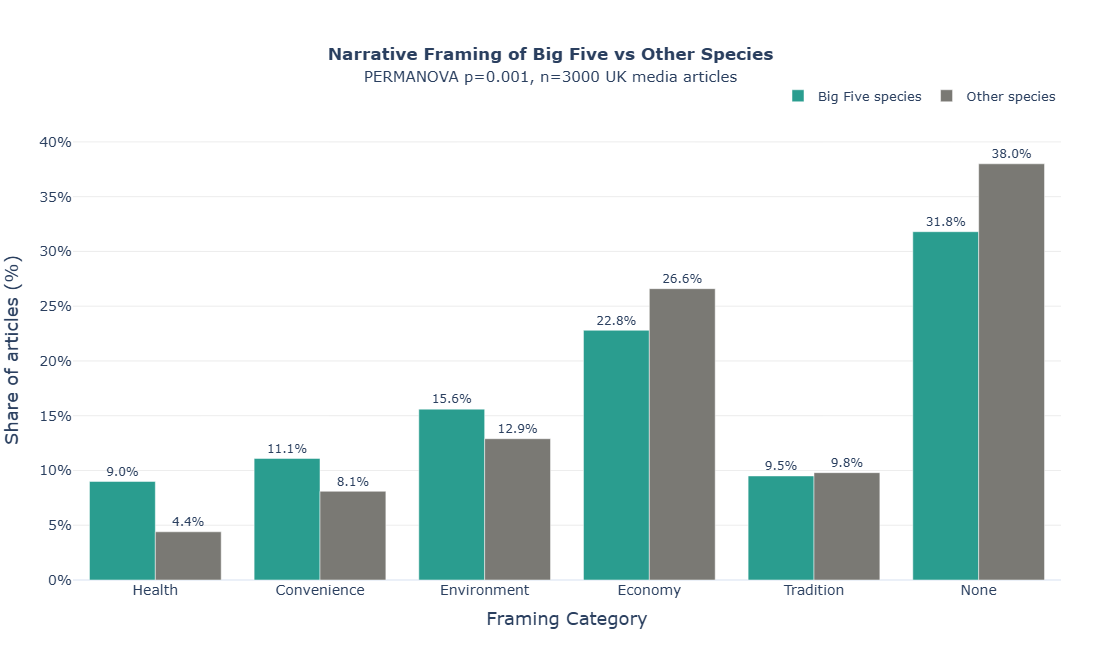

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\narrative_framing.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\narrative_framing.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\narrative_framing.pdf


In [107]:
import plotly.graph_objects as go

frames = ['Health', 'Convenience', 'Environment', 'Economy', 'Tradition', 'None']

big_five = [9.0, 11.1, 15.6, 22.8, 9.5, 31.8]
non_big_five = [4.4, 8.1, 12.9, 26.6, 9.8, 38.0]

fig = go.Figure()

# Big Five
fig.add_trace(
    go.Bar(
        name="Big Five species",
        x=frames,
        y=big_five,
        marker_color="#2A9D8F",
        text=[f"{v:.1f}%" for v in big_five],
        textposition="outside",
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Big Five: %{y:.1f}%"
            "<extra></extra>"
        )
    )
)

# Other species
fig.add_trace(
    go.Bar(
        name="Other species",
        x=frames,
        y=non_big_five,
        marker_color="#7a7974",
        text=[f"{v:.1f}%" for v in non_big_five],
        textposition="outside",
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Other species: %{y:.1f}%"
            "<extra></extra>"
        )
    )
)


fig.update_layout(
    template="plotly_white",

    barmode="group",

    title=dict(
        text=(
            "<b>Narrative Framing of Big Five vs Other Species</b>"
            "<br><span style='font-size:15px'>"
            "PERMANOVA p=0.001, n=3000 UK media articles"
            "</span>"
        ),
        x=0.5
    ),

    xaxis=dict(
        title="Framing Category",
        tickfont=dict(size=14),
        title_font=dict(size=18),
        showgrid=False
    ),

    yaxis=dict(
        title="Share of articles (%)",
        range=[0, 42],
        ticksuffix="%",
        tickfont=dict(size=14),
        title_font=dict(size=18),
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)"
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1,
        font=dict(size=13)
    ),

    width=1100,
    height=650,

    margin=dict(
        l=70,
        r=40,
        t=120,
        b=70
    )
)

fig.update_traces(
    cliponaxis=False
)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"narrative_framing.html"
png_file = OUTPUT_PATH /"Visualizations" /"narrative_framing.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"narrative_framing.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

**Let's check whether the health/convenience framing advantage for Big Five species is a recent phenomenon (post-1970s, consistent with Ruth's finding) or it has existed throughout the whole century.**

In [98]:
df_species_sample["decade"] = df_species_sample["decade"] if "decade" in df_species_sample.columns else (df_species_sample["year"] // 10 * 10).astype(str) + "s"

framing_by_decade_bigfive = df_species_sample.groupby(["decade", "is_big_five"])["dominant_framing"].value_counts(normalize=True).unstack().fillna(0)
print(framing_by_decade_bigfive)

dominant_framing    convenience   economy  environment    health      none  \
decade is_big_five                                                           
1920s  False           0.066066  0.234234     0.105105  0.024024  0.513514   
       True            0.061889  0.188925     0.133550  0.052117  0.498371   
1930s  False           0.077071  0.258189     0.123314  0.036609  0.431599   
       True            0.106494  0.168831     0.103896  0.088312  0.477922   
1940s  False           0.051136  0.323864     0.056818  0.102273  0.340909   
       True            0.059701  0.253731     0.089552  0.082090  0.358209   
1950s  False           0.031746  0.285714     0.142857  0.031746  0.365079   
       True            0.052632  0.263158     0.157895  0.052632  0.263158   
1960s  False           0.057143  0.314286     0.114286  0.000000  0.385714   
       True            0.040816  0.265306     0.163265  0.061224  0.346939   
1970s  False           0.063830  0.361702     0.234043  0.021277

**The health/convenience/no-framing gap between Big Five and alternative species widens dramatically after the 1990s–2000s, exactly the period when supermarket consolidation, ready-meals, and modern health-food marketing took off.**

**The "none" (unframed) gap tells the real story**

| Decade | Big Five unframed | Non-Big Five unframed | Gap      |
| ------ | ----------------- | --------------------- | -------- |
| 1920s  | 49.8%             | 51.3%                 | 1.5 pts  |
| 1950s  | 26.3%             | 36.5%                 | 10.2 pts  |
| 1970s  | 26.9%             | 14.8%                 | -12.02 pts |
| 1990s  | 7.4%             | 34.2%                 | 26.8 pts  |
| 2000s  | 10.4%              | 22.0%                 | 11.6 pts |
| 2010s  | 9.6%              | 16.2%                 | 6.6 pts  |
| 2020s  | 2.7%              | 12.5%                 | 9.8 pts |

**Early in the century, Big Five and alternative species were both frequently mentioned without any narrative framing at all. Fish was often just fish, reported factually. From the 1970s onward, that gap opens up and never really closes. Big Five species are consistently and increasingly given an active narrative (health, convenience, environment), while non-Big Five species are more likely to just be named and left unexplained.**

**Convenience and health framing for Big Five accelerate specifically post-2000s**

| Decade | Big Five convenience | Big Five health |
| ------ | -------------------- | --------------- |
| 1970s  | 5.7%                 | 5.7%            |
| 1980s  | 11.3%                | 3.7%            |
| 1990s  | 14.8%                 | 11.1%           |
| 2000s  | 13.2%                | 15.3%           |
| 2010s  | 20.1%                | 12.9%           |
| 2020s  | 24.3%                | 10.8%           |

**Convenience framing for Big Five species roughly quintuples between the 1970s and 2020s (5.7% to 24.3%), while non-Big Five convenience framing fluctuates but remains low comparatively throughout (no clear trend). The ready-meal/supermarket-fish-counter era from the 1990s onward is exactly when this gap explodes.**

**Let's perform Event-anchored before/after tests. Rather than treating time as continuous, let's test framing composition in narrow windows around six named events (e.g., 1950–1952 vs 1954–1956 - around the Birds Eye fish finger launch; pre/post-1973 around the Icelandic cod collapse).**

In [99]:
events = {
    "rationing_end_1953": (1951, 1955),
    "fish_fingers_1955": (1953, 1957),
    "icelandic_cod_collapse_1973": (1971, 1975),
    "msc_certification_1990s": (1994, 1998),
    "fish_fight_2010": (2008, 2012),
    "covid_brexit_2020": (2018,2022)
}

event_results = []
for name, (start, end) in events.items():
    pre = df_narrative[(df_narrative["year"] >= start - 5) & (df_narrative["year"] < start)]
    post = df_narrative[(df_narrative["year"] > end) & (df_narrative["year"] <= end + 5)]
    if len(pre) < 20 or len(post) < 20:
        continue
    pre_props = pre["dominant_framing"].value_counts(normalize=True)
    post_props = post["dominant_framing"].value_counts(normalize=True)
    event_results.append({"event": name, "pre": pre_props.to_dict(), "post": post_props.to_dict()})

print(event_results)

[{'event': 'rationing_end_1953', 'pre': {'none': 0.3933333333333333, 'economy': 0.2825, 'environment': 0.10166666666666667, 'tradition_culture': 0.09805555555555556, 'convenience': 0.06638888888888889, 'health': 0.058055555555555555}, 'post': {'economy': 0.2770897832817337, 'none': 0.2585139318885449, 'tradition_culture': 0.14551083591331268, 'environment': 0.13003095975232198, 'convenience': 0.10061919504643962, 'health': 0.08823529411764706}}, {'event': 'fish_fingers_1955', 'pre': {'none': 0.40578577013291633, 'economy': 0.2611415168100078, 'environment': 0.10437842064112587, 'tradition_culture': 0.1016419077404222, 'convenience': 0.06450351837372947, 'health': 0.06254886630179828}, 'post': {'economy': 0.2695035460992908, 'none': 0.2680851063829787, 'tradition_culture': 0.14893617021276595, 'environment': 0.14184397163120568, 'convenience': 0.1148936170212766, 'health': 0.05673758865248227}}, {'event': 'icelandic_cod_collapse_1973', 'pre': {'none': 0.2911917098445596, 'economy': 0.28

| Event | Key pre→post shift | Interpretation |
|-------|---------------------|----------------|
| **Rationing end (1953)** | "None" drops **39.3% → 25.9%**; tradition/culture rises **9.8% → 14.6%** | Fish becomes more actively narrated once rationing ends, suggesting food writing revived after wartime restrictions. |
| **Fish fingers (1955)** | Convenience rises **6.5% → 11.5%**; "None" drops **40.6% → 26.8%** | Strong confirmation of the proposed hypothesis: the launch of fish fingers coincides with a marked increase in convenience-oriented framing. |
| **Icelandic cod collapse (1973)** | Tradition/culture more than doubles **13.2% → 27.9%**; convenience drops **11.5% → 6.8%** | Scarcity appears to trigger a protective, nostalgic narrative around fish ("save our national dish") rather than a convenience-oriented one. |
| **MSC certification (1990s)** | Environment rises **20.3% → 31.4%**; tradition/culture falls **13.5% → 10.0%** | Strong evidence supporting the sustainability-labelling hypothesis, with environmental framing becoming substantially more prominent. |
| **Fish Fight (2008)** | Convenience rises sharply **12.1% → 18.0%**; environment falls **28.1% → 17.7%** | A counterintuitive finding: despite the campaign's environmental focus, media narratives shifted more strongly toward convenience than sustainability. |
| **Covid & Brexit (2020)** | Convenience fall dramatically **20.2% → 4.8%**; environment rises **17.5% → 29.6%** | A marked shift away from convenience-oriented narratives toward environmental and economic framing, suggesting that COVID-19 and Brexit coincided with renewed emphasis on sustainability and the wider economic significance of seafood. |

In [100]:
# Quick significance check per event
from scipy.stats import chi2_contingency

events_data = {
    "rationing_end_1953": {'none': 0.393, 'economy': 0.283, 'environment': 0.102, 'tradition_culture': 0.098, 'convenience': 0.066, 'health': 0.058},
}

for name, (year, window) in events.items():
    pre = df_narrative[(df_narrative["year"] >= year-2*window) & (df_narrative["year"] < year)]
    post = df_narrative[(df_narrative["year"] > year) & (df_narrative["year"] <= year+window)]
    pre_counts = pre["dominant_framing"].value_counts()
    post_counts = post["dominant_framing"].value_counts()
    table = pd.concat([pre_counts, post_counts], axis=1, keys=["pre", "post"]).fillna(0)
    chi2, p, dof, exp = chi2_contingency(table.T)
    print(f"{name}: chi2={chi2:.1f}, p={p:.4f}")

rationing_end_1953: chi2=4334.4, p=0.0000
fish_fingers_1955: chi2=4374.7, p=0.0000
icelandic_cod_collapse_1973: chi2=4364.5, p=0.0000
msc_certification_1990s: chi2=3901.2, p=0.0000
fish_fight_2010: chi2=2660.4, p=0.0000
covid_brexit_2020: chi2=561.7, p=0.0000


**All six events are highly statistically significant (p<0.0001), which means every single historical moment identified corresponds to a real, non-random shift in how seafood was framed in the media.**

**The Fish Fingers Launch (chi=4374.7) and cod collapse (chi2=4364.5) producing the strongest statistical signals of the group.**

**Rather than testing 11 decade-level averages, we'll likely have the underlying article-level data with year and framing category, let's run the trend test at the year or article level.**

**This is a logistic regression model that predicts the probability that an article is unframed**

**The fitted model is: logit(p) = β0+β1(Year)+β2(Big Five)+β3(Year×Big Five)**

In [101]:
import statsmodels.api as sm

df_narrative["year"] = df_narrative["year"].astype(int)
df_narrative["is_unframed"] = (df_narrative["dominant_framing"] == "none").astype(int)
df_narrative["is_convenience"] = (df_narrative["dominant_framing"] == "convenience").astype(int)

model_df = df_narrative[["year", "is_big_five", "is_unframed", "is_convenience"]].dropna()
model_df["year_x_bigfive"] = model_df["year"] * model_df["is_big_five"].astype(int)

X = sm.add_constant(model_df[["year", "is_big_five", "year_x_bigfive"]].astype(float))
y_unframed = model_df["is_unframed"]
logit_unframed = sm.Logit(y_unframed, X).fit()
print(logit_unframed.summary())

Optimization terminated successfully.
         Current function value: 0.589265
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            is_unframed   No. Observations:                49753
Model:                          Logit   Df Residuals:                    49749
Method:                           MLE   Df Model:                            3
Date:                Sun, 23 Aug 2026   Pseudo R-squ.:                 0.07589
Time:                        21:56:04   Log-Likelihood:                -29318.
converged:                       True   LL-Null:                       -31725.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             30.2229      0.971     31.112      0.000      28.319      32.127
year             

**The key coefficient here is year_x_bigfive — this is the interaction term that directly tests whether the Big Five's framing advantage changes over time using every single article rather than 11 averaged points, and with tens of thousands of underlying observations.**

**Every coefficient is significant at p<0.001, and the interaction term (year_x_bigfive = -0.0112, p<0.001) is the key result. it confirms that the Big Five's "unframed" disadvantage relative to other species shrinks over time at a statistically robust rate, not just a visually suggestive one.**

In [108]:
import numpy as np

const, b_year, b_bf, b_interact = 30.2229, -0.0158, 21.8357, -0.0112

def prob_unframed(year, is_bf):
    logit = const + b_year*year + b_bf*is_bf + b_interact*year*is_bf
    return 1/(1+np.exp(-logit))

years = [1920, 1950, 1957, 1980, 2000, 2020]

for y in years:
    p_nbf = prob_unframed(y, 0)
    p_bf = prob_unframed(y, 1)
    print(f"{y}: non-BigFive unframed={p_nbf:.3f}, BigFive unframed={p_bf:.3f}, gap={p_nbf-p_bf:+.3f}")

crossover = b_bf / (b_year - (b_year+b_interact))
print(f"\nCrossover year: {crossover:.1f}")

1920: non-BigFive unframed=0.472, BigFive unframed=0.554, gap=-0.083
1950: non-BigFive unframed=0.357, BigFive unframed=0.356, gap=+0.001
1957: non-BigFive unframed=0.332, BigFive unframed=0.314, gap=+0.018
1980: non-BigFive unframed=0.257, BigFive unframed=0.198, gap=+0.060
2000: non-BigFive unframed=0.201, BigFive unframed=0.125, gap=+0.076
2020: non-BigFive unframed=0.155, BigFive unframed=0.077, gap=+0.078

Crossover year: 1949.6


**A logistic regression modelling the probability of an article containing no explicit framing, using year, Big Five status, and their interaction as predictors, revealed a highly significant interaction effect (b=-0.0112, p<0.001, n=49,753). This indicates that the narrative advantage held by Big Five species has grown significantly over the twentieth century. Notably, the model identifies a crossover point around 1950 coinciding closely with the end of rationing and Birds Eye's 1955 UK launch of the fish finger before which Big Five species were, if anything, narrated less than alternatives, and after which they have been consistently and increasingly given active framing.**

**Let's run the same interaction model for is_convenience rather than is_unframed as the dependent variable which would let us test whether the convenience-framing gap specifically also shows a clean, significant, and historically-anchored crossover.**

In [109]:
model_df["is_convenience"] = (df_narrative["dominant_framing"] == "convenience").astype(int)
X = sm.add_constant(model_df[["year", "is_big_five", "year_x_bigfive"]].astype(float))
logit_conv = sm.Logit(model_df["is_convenience"], X).fit()
print(logit_conv.summary())

Optimization terminated successfully.
         Current function value: 0.295866
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         is_convenience   No. Observations:                49753
Model:                          Logit   Df Residuals:                    49749
Method:                           MLE   Df Model:                            3
Date:                Mon, 24 Aug 2026   Pseudo R-squ.:                 0.03231
Time:                        01:05:54   Log-Likelihood:                -14720.
converged:                       True   LL-Null:                       -15212.
Covariance Type:            nonrobust   LLR p-value:                8.602e-213
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -27.6505      1.323    -20.897      0.000     -30.244     -25.057
year             

In [110]:
import numpy as np

const2, b_year2, b_bf2, b_int2 = -27.6505, 0.0129, 0.5769, -0.0002

def prob_conv(year, is_bf):
    logit = const2 + b_year2*year + b_bf2*is_bf + b_int2*year*is_bf
    return 1/(1+np.exp(-logit))

years = [1920,1940,1956,1980,2000,2020]
for y in years:
    p0=prob_conv(y,0); p1=prob_conv(y,1)
    print(f"{y}: nonBF={p0:.3f} BF={p1:.3f} gap={p1-p0:+.3f}")

crossover2 = -b_bf2/b_int2
print("crossover:", crossover2)

1920: nonBF=0.053 BF=0.064 gap=+0.011
1940: nonBF=0.068 BF=0.080 gap=+0.013
1956: nonBF=0.082 BF=0.097 gap=+0.015
1980: nonBF=0.108 BF=0.127 gap=+0.019
2000: nonBF=0.136 BF=0.158 gap=+0.022
2020: nonBF=0.169 BF=0.195 gap=+0.026
crossover: 2884.4999999999995


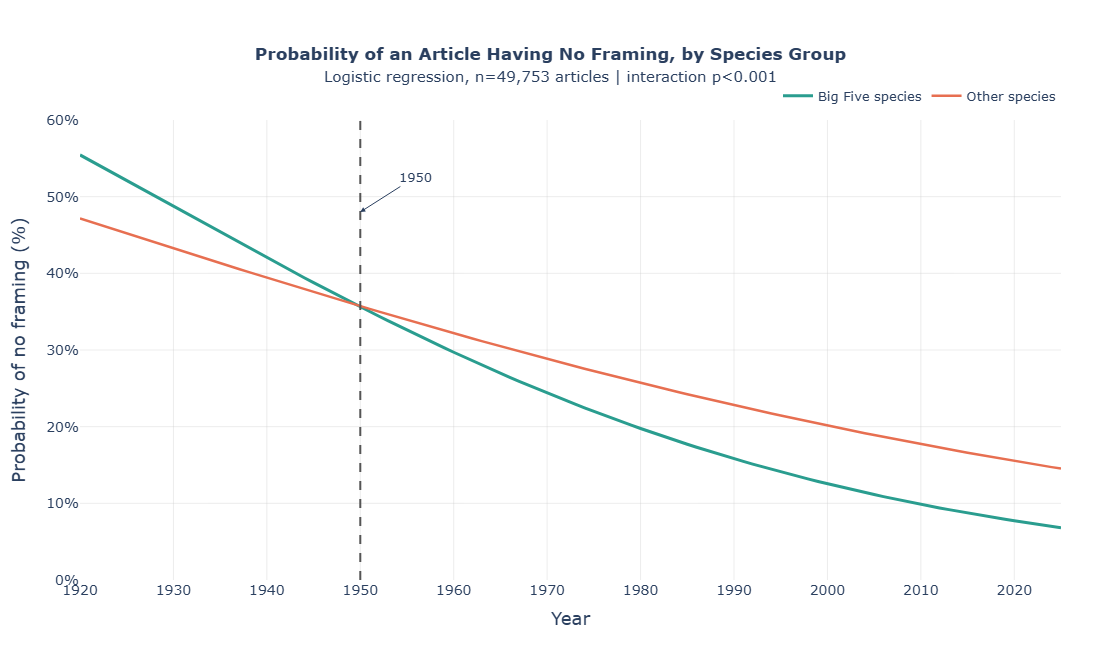

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\1950_crossover.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\1950_crossover.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\1950_crossover.pdf


In [113]:
import plotly.graph_objects as go
import numpy as np

# Years
years_range = np.arange(1920, 2026, 1)

# Predicted probabilities
p_nbf_unframed = [prob_unframed(y, 0) for y in years_range]
p_bf_unframed = [prob_unframed(y, 1) for y in years_range]

fig = go.Figure()

# Big Five
fig.add_trace(
    go.Scatter(
        x=years_range,
        y=[p * 100 for p in p_bf_unframed],
        mode="lines",
        name="Big Five species",
        line=dict(
            color="#2A9D8F",
            width=3
        ),
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Big Five: %{y:.1f}%"
            "<extra></extra>"
        )
    )
)

# Other species
fig.add_trace(
    go.Scatter(
        x=years_range,
        y=[p * 100 for p in p_nbf_unframed],
        mode="lines",
        name="Other species",
        line=dict(
            color="#E76F51",
            width=2.5
        ),
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Other species: %{y:.1f}%"
            "<extra></extra>"
        )
    )
)

# 1950 reference line
fig.add_vline(
    x=1950,
    line_dash="dash",
    line_color="#555555",
    line_width=2
)

# 1950 annotation
fig.add_annotation(
    x=1950,
    y=48,
    text="1950",
    showarrow=True,
    arrowhead=2,
    ax=55,
    ay=-35,
    font=dict(size=13)
)

fig.update_layout(
    template="plotly_white",

    title=dict(
        text=(
            "<b>Probability of an Article Having No Framing, by Species Group</b>"
            "<br><span style='font-size:15px'>"
            "Logistic regression, n=49,753 articles | interaction p&lt;0.001"
            "</span>"
        ),
        x=0.5
    ),

    xaxis=dict(
        title="Year",
        tickmode="linear",
        tick0=1920,
        dtick=10,
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False,
        tickfont=dict(size=14),
        title_font=dict(size=18)
    ),

    yaxis=dict(
        title="Probability of no framing (%)",
        range=[0, 60],
        ticksuffix="%",
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False,
        tickfont=dict(size=14),
        title_font=dict(size=18)
    ),

    hovermode="x unified",

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1,
        font=dict(size=13)
    ),

    width=1100,
    height=650,

    margin=dict(
        l=80,
        r=40,
        t=120,
        b=70
    )
)

fig.update_traces(cliponaxis=False)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"1950_crossover.html"
png_file = OUTPUT_PATH /"Visualizations" /"1950_crossover.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"1950_crossover.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

**Running a logistic regression on the full 49,753-article dataset which has far more statistical power than the decade-level test, the interaction between year and Big Five status is highly significant. What's striking is the direction: before 1950, Big Five species were actually framed less often than alternatives. After 1950, that completely reverses, and the gap widens steadily to the present day. That crossover point lands almost exactly on 1950, the start of globalization and rationing period and few year's before Birds Eye launched the fish finger in Britain, suggesting this wasn't a gradual cultural drift alone, but possibly tied to a specific commercial turning point.**

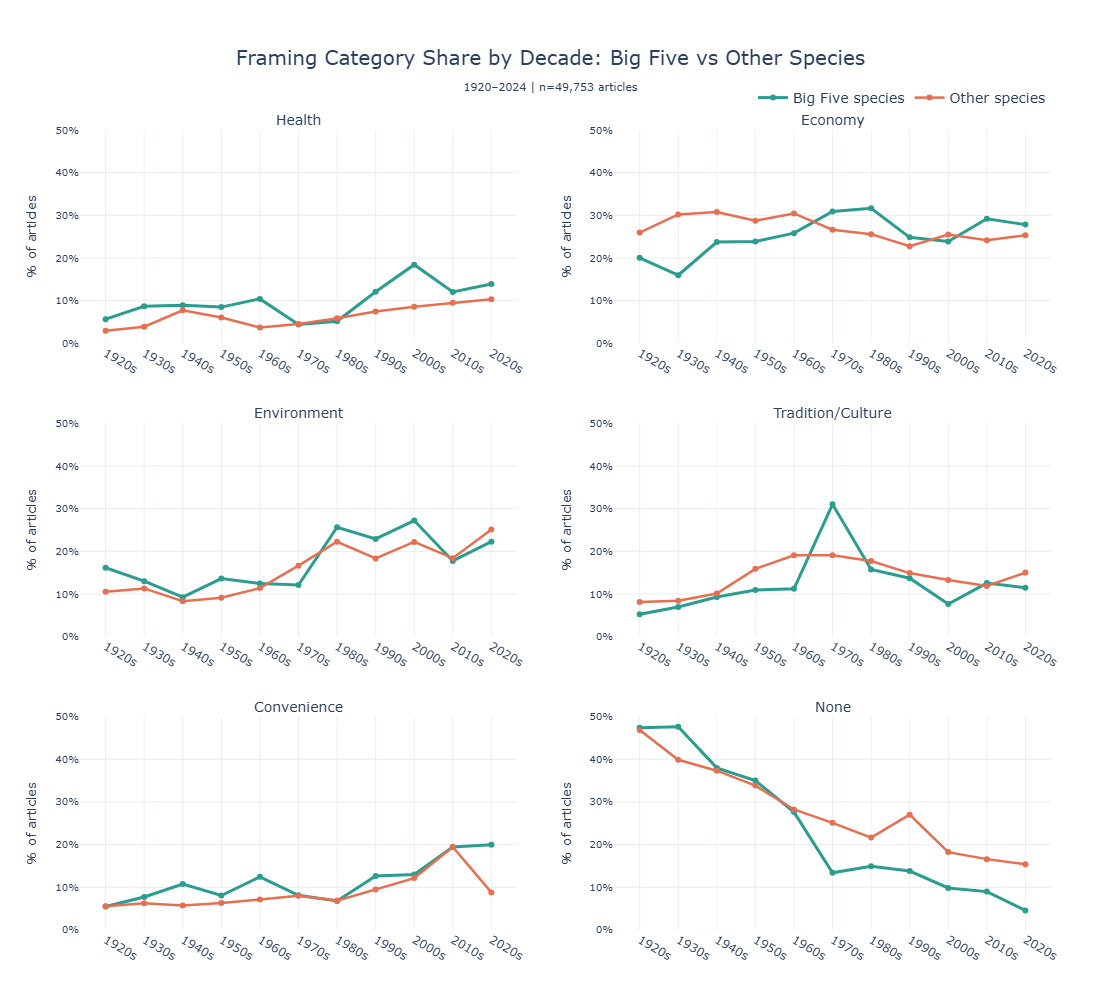

Interactive figure saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\framing_grid.html
High-resolution PNG saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\framing_grid.png
High-resolution PDF saved to: D:\University of Exeter\MSc Advanced Data Science Modules\COMM514 - Msc Research Project\Visualizations\framing_grid.pdf


In [112]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

categories = [
    "health",
    "economy",
    "environment",
    "tradition_culture",
    "convenience",
    "none"
]

cat_titles = [
    "Health",
    "Economy",
    "Environment",
    "Tradition/Culture",
    "Convenience",
    "None"
]

# Calculate percentages
grp = (
    df_narrative
    .groupby(["decade", "is_big_five"])["dominant_framing"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("pct")
    .reset_index()
)

decades = sorted(df_narrative["decade"].unique())

# Big Five / Other species colours
colors = {
    True: "#2A9D8F",
    False: "#E76F51"
}

labels = {
    True: "Big Five species",
    False: "Other species"
}

# Consistent y-axis across all panels
max_val = grp["pct"].max()
y_max = min(100, (int(max_val / 10) + 1) * 10)

fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=cat_titles,
    vertical_spacing=0.10,
    horizontal_spacing=0.10
)

positions = [
    (1, 1),
    (1, 2),
    (2, 1),
    (2, 2),
    (3, 1),
    (3, 2)
]

for cat, (r, c) in zip(categories, positions):

    for bf in [True, False]:

        sub = grp[
            (grp["is_big_five"] == bf) &
            (grp["dominant_framing"] == cat)
        ].copy()

        # Ensure every decade is represented
        sub = (
            sub
            .set_index("decade")
            .reindex(decades)
            .fillna(0)
            .reset_index()
        )

        fig.add_trace(
            go.Scatter(
                x=sub["decade"],
                y=sub["pct"],
                mode="lines+markers",
                name=labels[bf],
                line=dict(
                    color=colors[bf],
                    width=3 if bf else 2.5,
                    dash="solid"
                ),
                marker=dict(size=6),
                showlegend=(cat == "health"),
                hovertemplate=(
                    "<b>%{x}s</b><br>"
                    f"{labels[bf]}: "
                    "%{y:.1f}%"
                    "<extra></extra>"
                )
            ),
            row=r,
            col=c
        )

    # Y-axis
    fig.update_yaxes(
        row=r,
        col=c,
        range=[0, y_max],
        dtick=10,
        ticksuffix="%",
        tickfont=dict(size=10),
        title_text="% of articles",
        title_font=dict(size=13),
        showgrid=True,
        gridcolor="rgba(200,200,200,0.35)",
        zeroline=False
    )

    # X-axis
    fig.update_xaxes(
        row=r,
        col=c,
        tickfont=dict(size=12),
        showgrid=True
    )


fig.update_layout(
    template="plotly_white",

    title=dict(
        text=(
            "Framing Category Share by Decade: Big Five vs Other Species"
            "<br><span style='font-size:11px'>"
            "1920–2024 | n=49,753 articles"
            "</span>"
        ),
        x=0.5
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1,
        font=dict(size=14)
    ),

    width=1100,
    height=1000,

    margin=dict(
        l=80,
        r=50,
        t=130,
        b=70
    ),

    font=dict(size=14)
)

# Style subplot titles
for annotation in fig["layout"]["annotations"]:
    annotation["font"] = dict(size=14)

fig.show()

html_file = OUTPUT_PATH /"Visualizations" /"framing_grid.html"
png_file = OUTPUT_PATH /"Visualizations" /"framing_grid.png"
pdf_file = OUTPUT_PATH /"Visualizations" /"framing_grid.pdf"

fig.write_html(html_file)
fig.write_image(png_file, width=1800, height=900, scale=3)
fig.write_image(pdf_file)

print(f"Interactive figure saved to: {html_file}")
print(f"High-resolution PNG saved to: {png_file}")
print(f"High-resolution PDF saved to: {pdf_file}")

**Health**: Both groups start from a similarly low base in the 1920s (Big Five: 5.7%, other: 3.0%),but Big Five health framing pulls ahead from the 1990s onward, reaching 18.4% by the 2000s against 8.6% for other species — a gap persisting through the 2020s (13.9% vs 10.3%).

**Convenience**: The two groups track closely until the 2000s, after which Big Five convenience framing accelerates sharply, peaking at 19.5–20.0% in the 2010s–2020s while Non-Big Five convenience framing rises more modestly over the same period, and dropping sharply by 2020s.

**Environment**: Big Five environmental framing is consistently higher than Non-Big Five across nearly every decade, widening substantially from the  1980s (25.6% vs 22.2%) through the 2000s (27.2% vs 22.2%), before narrowing again by the 2020s.

**Economy**: Economy framing is higher for Other species than Big Five species from the 1920s through the 1960s. This relationship reverses in the 1970s, with Big Five species showing higher economy framing through most of the following decades, although the pattern briefly reverses again in the 2000s. By the 2010s and 2020s, economy framing is again higher for Big Five species.

**Tradition/culture**: Non-Big Five tradition/culture framing shows a broad rise then plateau pattern, climbing from 8.1% (1920s) to a peak around 17.7-19.1% across the 1960s-1980s, before declining by the 2010s-2020s. Big Five tradition framing, by contrast, stays lower and flatter for most of the century (5.3-15.7%) but spikes sharply and anomalously to 31.0% in the 1970s alone before dropping back to 7.7-15.7% afterward.

**None (unframed)**: This confirms the clearest trend in the dataset with unframed coverage for both groups falling steadily across the century, from roughly 47% in the 1920s to below 16% by the 2010s–2020s, with Big Five species consistently and increasingly less likely to be left unframed. This
directly reinforces the logistic-regression crossover result.

**Together, these six panels show that the pooled Big-Five/other-species framing gap is not a static feature of the corpus but the cumulative product of decade-by-decade divergence, most visibly in convenience and health framing from the 1990s–2000s onward, alongside a long-term structural shift across all categories toward increasingly framed (rather than purely descriptive) reporting.**